In [1]:
from utils import (load_counties, load_cbsa, set_plot_style,
                   SOC2_MAP, NRI_HAZARD_NAMES,
                   classify_per_window, compute_ccdf, gini)
import numpy as np
import pandas as pd
import geopandas as gpd

import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from adjustText import adjust_text

import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import LogLocator, ScalarFormatter

import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path
import scipy.stats as ss

from tqdm import trange

import io

import pickle

import networkx as nx

from scipy.stats import pearsonr

In [2]:
set_plot_style()


In [3]:
### LOADING DATA ###

counties = load_counties()

state_to_fips = {
    "AL": "01","AK": "02","AZ": "04","AR": "05","CA": "06","CO": "08","CT": "09",
    "DE": "10","DC": "11","FL": "12","GA": "13","HI": "15","ID": "16","IL": "17",
    "IN": "18","IA": "19","KS": "20","KY": "21","LA": "22","ME": "23","MD": "24",
    "MA": "25","MI": "26","MN": "27","MS": "28","MO": "29","MT": "30","NE": "31",
    "NV": "32","NH": "33","NJ": "34","NM": "35","NY": "36","NC": "37","ND": "38",
    "OH": "39","OK": "40","OR": "41","PA": "42","RI": "44","SC": "45","SD": "46",
    "TN": "47","TX": "48","UT": "49","VT": "50","VA": "51","WA": "53","WV": "54",
    "WI": "55","WY": "56","PR": "72"
}
fips_to_state = {v: k for k, v in state_to_fips.items()}

counties["STATE"] = counties["STATEFP"].map(fips_to_state)

counties["name"] = counties["NAME"] + ", " + counties["STATE"]


### Flows and PageRanks - all combined (2011-2022)

hits_exp_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_exp_1122.parquet")
flows_exp_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_flows_exp_1122.parquet")

hits_soc2_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_soc2_hits_exp_1122.parquet")
flows_soc2_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_soc2_flows_1122.parquet")

hits_irs_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_irs_1122.parquet")
flows_irs_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_flows_irs_1122.parquet")

hits_senior_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_seniority_hits_exp_1122.parquet")
flows_senior_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_seniority_flows_1122.parquet")




## PANEL 1

In [4]:
# ### RESUME - only on row data

# df_win=pd.read_parquet('../data_generated/df_win.parquet')

# df_win["soc2"] = df_win["Code_final"].astype(str).str.slice(0, 2)

# soc2_map = SOC2_MAP

# df_win["soc_broad"] = df_win["soc2"].map(soc2_map)
# df_win['next_soc_broad'] = df_win.groupby('PERSON_ID')['soc_broad'].shift(-1)

# counts = (
#     df_win[df_win["next_soc_broad"] != "No ONET code"]["next_soc_broad"]
#     .value_counts()
#     .head(12)
# )
# counts = counts.sort_values(ascending=True)
# counts.reset_index(drop=True)
# counts.to_csv('../data_generated/soc_broad_counts.csv')

### FLOWS

flows_irs=pd.read_parquet("../data_generated/network_metrics/cbsa2_flows_irs_1122.parquet")
flows_exp=pd.read_parquet("../data_generated/network_metrics/cbsa2_flows_exp_1122.parquet")

# flows_merged=flows_irs.merge(flows_exp, left_on=['STCOFIPS', 'STCOFIPS_next'], right_on=['STCOFIPS', 'STCOFIPS_next'], how='outer', suffixes=('_irs', '_exp')) ## outer for now
flows_merged=flows_irs.merge(flows_exp, left_on=['CBSA Code', 'CBSA Code_next'], right_on=['CBSA Code', 'CBSA Code_next'], how='outer', suffixes=('_irs', '_exp'))

flows_irs_sum=flows_irs.n.sum()
flows_exp_sum=flows_exp.n.sum()

flows_irs["n_norm"] = flows_irs["n"]/flows_irs_sum
flows_exp["n_norm"] = flows_exp["n"]/flows_exp_sum

G_irs = nx.DiGraph()
for _, row in flows_irs.iterrows():
    G_irs.add_edge(
        row["CBSA Code"],
        row["CBSA Code_next"],
        weight=row["n_norm"]
    )

G_exp = nx.DiGraph()
for _, row in flows_exp.iterrows():
    G_exp.add_edge(
        row["CBSA Code"],
        row["CBSA Code_next"],
        weight=row["n_norm"]
    )


# In-degree (weighted)
w_out_deg_irs = dict(G_irs.out_degree(weight="weight"))
w_in_deg_irs = dict(G_irs.in_degree(weight="weight"))

w_out_sorted_irs, w_out_ccdf_irs = compute_ccdf(w_out_deg_irs)
w_in_sorted_irs, w_in_ccdf_irs = compute_ccdf(w_in_deg_irs)

# Out-degree (weighted)
w_out_deg_exp = dict(G_exp.out_degree(weight="weight"))
w_in_deg_exp = dict(G_exp.in_degree(weight="weight"))

w_out_sorted_exp, w_out_ccdf_exp = compute_ccdf(w_out_deg_exp)
w_in_sorted_exp, w_in_ccdf_exp = compute_ccdf(w_in_deg_exp)


### NETWORK STATS

summary=pd.read_parquet('../data_generated/network_metrics/cbsa2_stats1_summary.parquet')

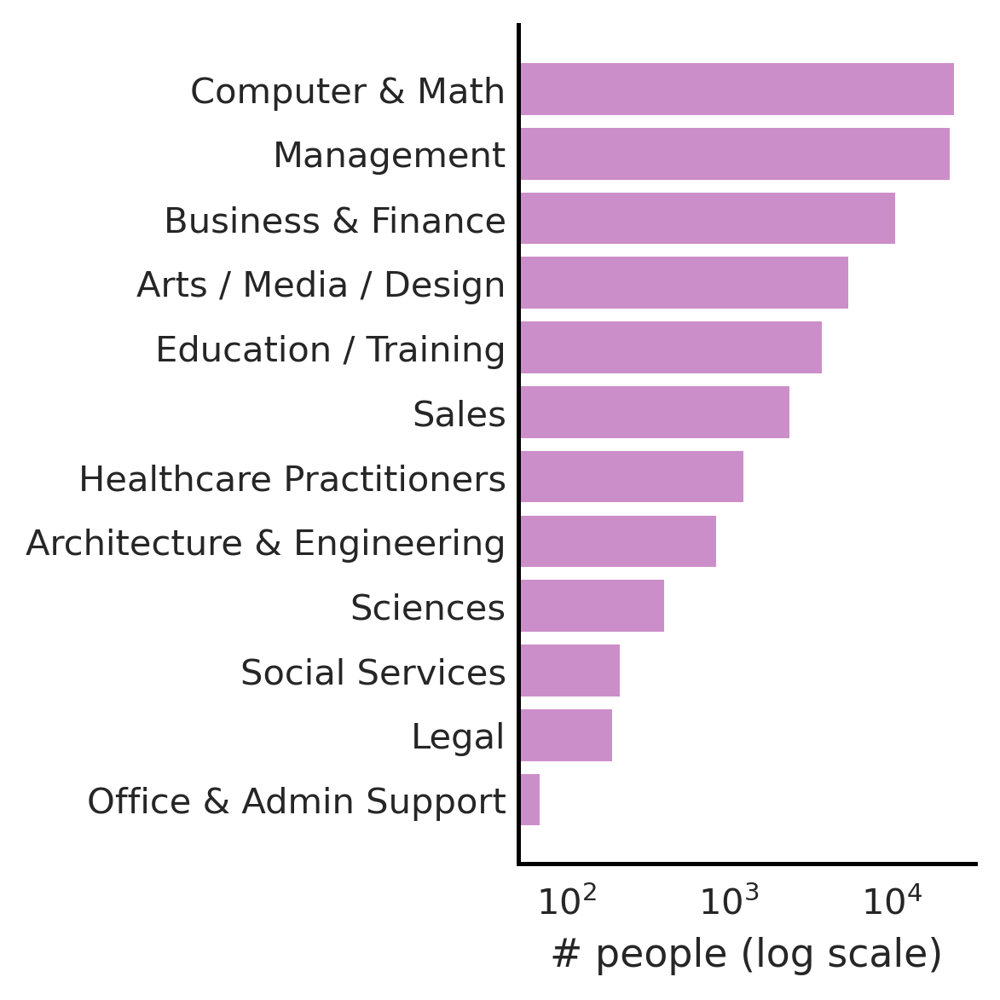

In [5]:
counts = pd.read_csv('../data_generated/soc_broad_counts.csv')

fig, ax = plt.subplots(figsize=(4, 4))

ax.barh(
    counts['next_soc_broad'],
    counts['count'],
    color="#C47AC0",
    edgecolor="none", 
    alpha=0.85
)

ax.set_xscale("log")
ax.set_xlabel("# people (log scale)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)


ax.tick_params(
    axis="y", length=0)
ax.tick_params(
    axis="x", width=0.6)

ax.set_facecolor("white")

plt.tight_layout()
plt.show()


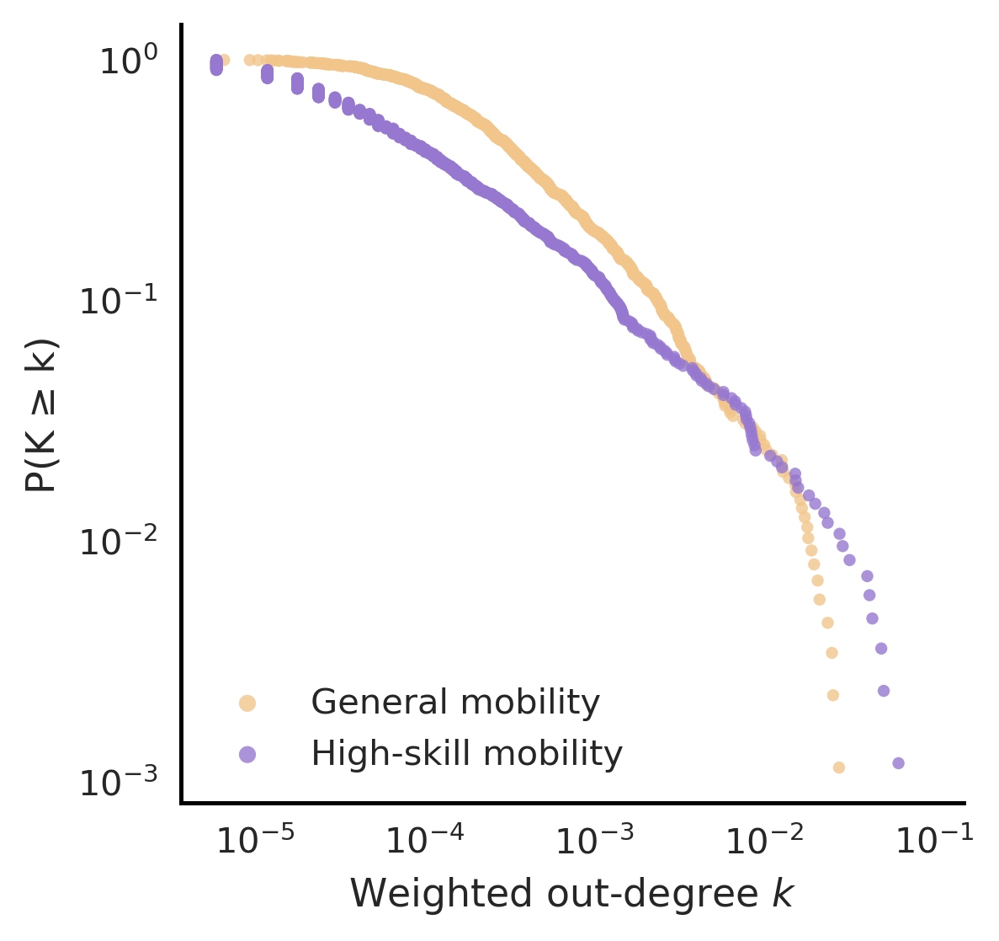

In [6]:
fig, ax = plt.subplots(figsize=(4, 4))

color_reg = '#f2c68b'
color_hs  = '#9678d1'

ax.scatter(
    w_out_sorted_irs, w_out_ccdf_irs,
    s=12, label="General mobility",
    alpha=0.8, color=color_reg, edgecolor="none"
)
ax.scatter(
    w_out_sorted_exp, w_out_ccdf_exp,
    s=12, label="High-skill mobility",
    alpha=0.8, color=color_hs, edgecolor="none"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Weighted out-degree $k$")
ax.set_ylabel("P(K ≥ k)")

ax.legend(
    frameon=False,
    loc='lower left',
    markerscale=1.4
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)

ax.tick_params(
    axis='both',
    which='both',
    length=3,
    width=0.6
)

In [7]:
summary

,exp_mean,exp_CI_low,exp_CI_high,exp_boot_mean,exp_bias,exp_boot_sd,exp_ci_method,irs_mean,irs_CI_low,irs_CI_high,irs_boot_mean,irs_bias,irs_boot_sd,irs_ci_method,diff_mean,diff_CI_low,diff_CI_high,significant
metric,,,,,,,,,,,,,,,,,,
strength_assort,-0.195379,-0.197749,-0.193010,-0.204731,-0.009352,0.001209,UNRELIABLE_bias_dominates_variance,-0.155188,-0.155224,-0.155152,-0.155188,-9.841294e-08,1.829254e-05,basic_bootstrap,-0.040191,-0.042597,-0.037785,True
degree_assort,-0.374517,-0.378772,-0.370261,-0.365767,0.008750,0.002171,UNRELIABLE_bias_dominates_variance,-0.203874,-0.203874,-0.203874,-0.203874,1.858000e-08,9.937797e-07,basic_bootstrap,-0.170642,-0.174897,-0.166387,True
w_core_ratio,29.709683,29.316456,30.702713,29.405734,-0.303949,0.349477,basic_bootstrap,21.067928,21.044336,21.092072,21.068405,4.773529e-04,1.221433e-02,basic_bootstrap,8.641755,8.224384,9.658378,True
core_ratio,2.795575,2.744538,2.846612,3.020631,0.225057,0.026039,UNRELIABLE_bias_dominates_variance,2.644862,2.644862,2.644862,2.644862,3.271320e-07,1.462979e-05,basic_bootstrap,0.150713,0.099676,0.201750,True
avg_w_clust,0.000836,0.000793,0.000879,0.001059,0.000223,0.000022,UNRELIABLE_bias_dominates_variance,0.000499,0.000498,0.000500,0.000498,-9.544053e-07,4.261621e-07,UNRELIABLE_bias_dominates_variance,0.000337,0.000293,0.000381,True


In [8]:
exp_mean = 0.653
irs_mean = 0.737
diff_mean = exp_mean - irs_mean

new_row = pd.DataFrame({
    "exp_mean":      [exp_mean],
    "exp_CI_low":    [0],
    "exp_CI_high":   [0],
    "irs_mean":      [irs_mean],
    "irs_CI_low":    [0],
    "irs_CI_high":   [0],
    "diff_mean":     [diff_mean],
    "diff_CI_low":   [0],
    "diff_CI_high":  [0],
    "significant":   [True]
}, index=["avg_clust"])

summary = pd.concat([summary, new_row])
summary

,exp_mean,exp_CI_low,exp_CI_high,exp_boot_mean,exp_bias,exp_boot_sd,exp_ci_method,irs_mean,irs_CI_low,irs_CI_high,irs_boot_mean,irs_bias,irs_boot_sd,irs_ci_method,diff_mean,diff_CI_low,diff_CI_high,significant
strength_assort,-0.195379,-0.197749,-0.193010,-0.204731,-0.009352,0.001209,UNRELIABLE_bias_dominates_variance,-0.155188,-0.155224,-0.155152,-0.155188,-9.841294e-08,1.829254e-05,basic_bootstrap,-0.040191,-0.042597,-0.037785,True
degree_assort,-0.374517,-0.378772,-0.370261,-0.365767,0.008750,0.002171,UNRELIABLE_bias_dominates_variance,-0.203874,-0.203874,-0.203874,-0.203874,1.858000e-08,9.937797e-07,basic_bootstrap,-0.170642,-0.174897,-0.166387,True
w_core_ratio,29.709683,29.316456,30.702713,29.405734,-0.303949,0.349477,basic_bootstrap,21.067928,21.044336,21.092072,21.068405,4.773529e-04,1.221433e-02,basic_bootstrap,8.641755,8.224384,9.658378,True
core_ratio,2.795575,2.744538,2.846612,3.020631,0.225057,0.026039,UNRELIABLE_bias_dominates_variance,2.644862,2.644862,2.644862,2.644862,3.271320e-07,1.462979e-05,basic_bootstrap,0.150713,0.099676,0.201750,True
avg_w_clust,0.000836,0.000793,0.000879,0.001059,0.000223,0.000022,UNRELIABLE_bias_dominates_variance,0.000499,0.000498,0.000500,0.000498,-9.544053e-07,4.261621e-07,UNRELIABLE_bias_dominates_variance,0.000337,0.000293,0.000381,True
avg_clust,0.653000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.737000,0.000000,0.000000,NaN,NaN,NaN,NaN,-0.084000,0.000000,0.000000,True


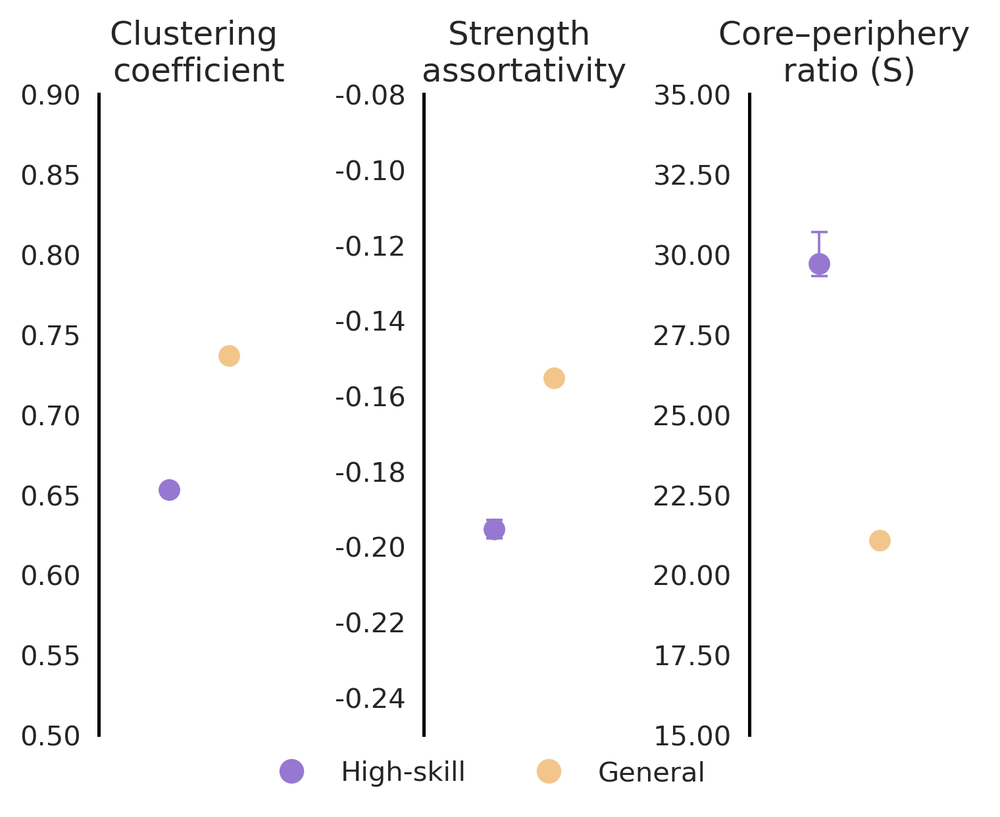

In [9]:
metrics_focus = ["avg_clust", "strength_assort", "w_core_ratio"]
pretty_titles = {
    "avg_clust":  "Clustering \ncoefficient",
    "strength_assort": "Strength \nassortativity",
    "w_core_ratio": "Core–periphery \nratio (S)"
}


fig, axes = plt.subplots(1, 3, figsize=(5, 4), sharey=False)
plt.subplots_adjust(wspace=0.40)


for ax, metric in zip(axes, metrics_focus):

    exp_mean = summary.loc[metric, "exp_mean"]
    exp_low  = summary.loc[metric, "exp_CI_low"]
    exp_high = summary.loc[metric, "exp_CI_high"]

    irs_mean = summary.loc[metric, "irs_mean"]
    irs_low  = summary.loc[metric, "irs_CI_low"]
    irs_high = summary.loc[metric, "irs_CI_high"]

    # ----- NEW: ignore bars for avg_clust -----
    if metric == "avg_clust":
        exp_err = None
        irs_err = None
    else:
        exp_err = [[exp_mean - exp_low], [exp_high - exp_mean]]
        irs_err = [[irs_mean - irs_low], [irs_high - irs_mean]]

    xpos = [0.35, 0.65]

    # High-skill
    ax.errorbar(
        xpos[0], exp_mean,
        yerr=exp_err,
        fmt='o', ms=7,
        color=color_hs,
        capsize=3,
        elinewidth=0.9,
        markeredgewidth=0.9,
        markerfacecolor=color_hs,
        markeredgecolor=color_hs,
        zorder=3
    )

    # General
    ax.errorbar(
        xpos[1], irs_mean,
        yerr=irs_err,
        fmt='o', ms=7,
        color=color_reg,
        capsize=3,
        elinewidth=0.9,
        markeredgewidth=0.9,
        markerfacecolor=color_reg,
        markeredgecolor=color_reg,
        zorder=3
    )

    ax.set_xlim(0, 1)
    ax.set_xticks([])
    ax.grid(False)

    for spine in ["top", "right", "bottom"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_linewidth(1.2)

    ax.tick_params(axis="y", which="both", length=3, width=0.6)
    ax.tick_params(axis="x", length=0)

    ax.set_title(pretty_titles[metric], pad=5)

# Share Legend
handles = [
    plt.Line2D([0],[0], marker='o', color='none',
               markerfacecolor=color_hs, markeredgecolor=color_hs,
               markersize=8, label="High-skill"),
    plt.Line2D([0],[0], marker='o', color='none',
               markerfacecolor=color_reg, markeredgecolor=color_reg,
               markersize=8, label="General"),
]

fig.legend(
    handles=handles,
    labels=["High-skill", "General"],
    loc="lower center",
    frameon=False,
    ncol=2,
    bbox_to_anchor=(0.5, -0.04)
)

ylims = {
    "avg_clust": (0.5, 0.9),
    "strength_assort": (-0.25, -0.08),
    "w_core_ratio": (15, 35)
}

for ax, metric in zip(axes, metrics_focus):
    ax.set_ylim(*ylims[metric])

# Format tick labels to always show two decimals
from matplotlib.ticker import FuncFormatter
fmt_ticks = lambda x, pos: f"{x:.2f}"

for ax in axes:
    ax.yaxis.set_major_formatter(FuncFormatter(fmt_ticks))

plt.tight_layout()
plt.show()

In [10]:
summary_by_field=pd.read_parquet('../data_generated/network_metrics/cbsa2_stats1_summary_by_field.parquet')
summary_by_seniority=pd.read_parquet('../data_generated/network_metrics/cbsa2_stats1_summary_by_seniority.parquet')

In [11]:
summary_by_field

mean     CI_low    CI_high  \
category                   metric                                             
Architecture & Engineering avg_w_clust       0.008837   0.006790   0.011417   
                           core_ratio        3.422687   3.137838   3.734033   
                           degree_assort    -0.131209  -0.157481  -0.102650   
                           strength_assort  -0.114647  -0.137220  -0.090783   
                           w_core_ratio     11.201150   9.832657  12.913030   
Arts / Media / Design      avg_w_clust       0.003991   0.003473   0.004619   
                           core_ratio        4.067405   3.909341   4.237628   
                           degree_assort    -0.227230  -0.239025  -0.215503   
                           strength_assort  -0.171313  -0.178599  -0.163665   
                           w_core_ratio     23.444846  21.781476  25.229354   
Business & Finance         avg_w_clust       0.007794   0.006770   0.008891   
                           core_ratio        4.389142   4.238349   4.553499   
                           degree_assort    -0.245580  -0.256867  -0.234557   
                           strength_assort  -0.200959  -0.208111  -0.193841   
                           w_core_ratio     16.689386  15.753999  17.705701   
Computer & Math            avg_w_clust       0.001880   0.001760   0.001999   
                           core_ratio        3.766111   3.668197   3.873499   
                           degree_assort    -0.366632  -0.373983  -0.359304   
                           strength_assort  -0.232897  -0.237652  -0.228036   
                           w_core_ratio     27.901861  27.084517  28.790091   
Education / Training       avg_w_clust       0.005798   0.004974   0.006845   
                           core_ratio        4.039192   3.865537   4.235379   
                           degree_assort    -0.214061  -0.228892  -0.199909   
                           strength_assort  -0.190312  -0.201473  -0.180466   
                           w_core_ratio     16.699668  15.678053  17.841262   
Healthcare Practitioners   avg_w_clust       0.021993   0.014791   0.031235   
                           core_ratio        3.538353   3.318227   3.767993   
                           degree_assort    -0.051933  -0.076637  -0.025655   
                           strength_assort  -0.042833  -0.066584  -0.017575   
                           w_core_ratio      6.353107   5.654883   7.256441   
Legal                      avg_w_clust       0.022903   0.013546   0.034380   
                           core_ratio        2.681805   2.456133   3.021429   
                           degree_assort    -0.087950  -0.131950  -0.040794   
                           strength_assort  -0.072312  -0.114932  -0.029229   
                           w_core_ratio      5.994952   5.004566   7.246575   
Management                 avg_w_clust       0.003473   0.003198   0.003787   
                           core_ratio        3.868704   3.754582   3.981955   
                           degree_assort    -0.340623  -0.347746  -0.333661   
                           strength_assort  -0.228885  -0.233660  -0.224063   
                           w_core_ratio     22.474518  21.740356  23.234866   
Sales                      avg_w_clust       0.011103   0.008558   0.014484   
                           core_ratio        3.989420   3.837441   4.184968   
                           degree_assort    -0.240739  -0.257450  -0.223767   
                           strength_assort  -0.199591  -0.212929  -0.186979   
                           w_core_ratio     12.178337  11.382447  13.186534   
Sciences                   avg_w_clust       0.024771   0.016139   0.035278   
                           core_ratio        3.038758   2.700696   3.260076   
                           degree_assort    -0.057686  -0.093972  -0.020367   
                           strength_assort  -0.044344  -0.079937  -0.009424   
                    

In [12]:
# Extract assortativity and core-periphery values per field

summary_by_field.index = summary_by_field.index.set_names(["job_field", "metric"])
fields = summary_by_field.index.levels[0]

assort_mean = []
assort_low = []
assort_high = []

core_mean = []
core_low = []
core_high = []

for field in fields:
    # assortativity
    a = summary_by_field.loc[(field, "strength_assort")]
    assort_mean.append(a["mean"])
    assort_low.append(a["CI_low"])
    assort_high.append(a["CI_high"])

    # core–periphery ratio
    c = summary_by_field.loc[(field, "w_core_ratio")]
    core_mean.append(c["mean"])
    core_low.append(c["CI_low"])
    core_high.append(c["CI_high"])

assort_mean = np.array(assort_mean)
assort_low  = np.array(assort_low)
assort_high = np.array(assort_high)

core_mean = np.array(core_mean)
core_low  = np.array(core_low)
core_high = np.array(core_high)

# Compute asymmetric error bars
assort_err = np.vstack([assort_mean - assort_low, assort_high - assort_mean])
core_err   = np.vstack([core_mean   - core_low,   core_high   - core_mean])

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


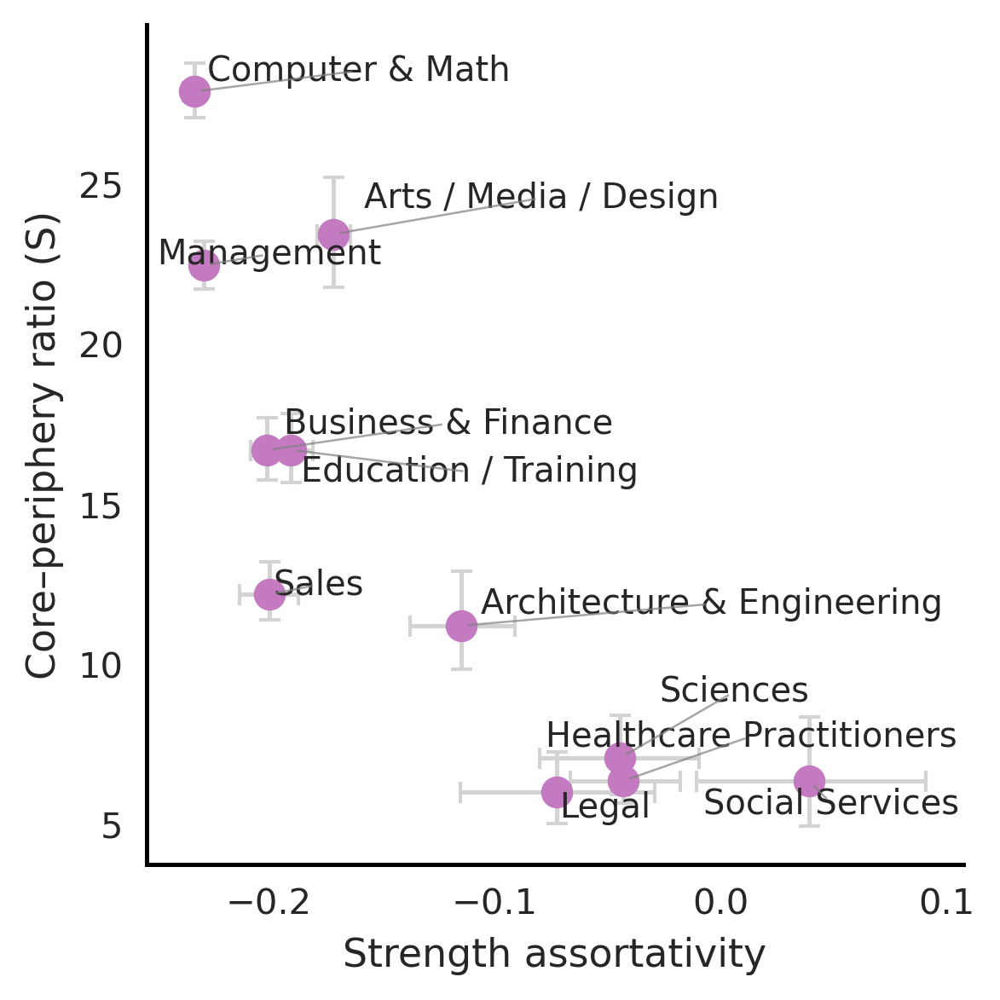

In [13]:
fig, ax = plt.subplots(figsize=(4, 4))

ax.errorbar(
    assort_mean,
    core_mean,
    xerr=assort_err,
    yerr=core_err,
    fmt="o",
    markersize=8,
    ecolor="lightgray",
    capsize=3,
    color="#C47AC0",
    alpha=1,
)

# --- Add text labels using adjustText ---
texts = []
for x, y, label in zip(assort_mean, core_mean, fields):
    t = ax.text(x, y, label)
    texts.append(t)

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.6, alpha=0.7),

    # Make labels push away harder
    force_text=2.5,  

    # Increase minimum padding around labels
    expand_text=(1.6, 1.6),
    expand_points=(2.0, 2.0),

    # Increase iteration count for more stable separation
    iterations=200, 

    # Make the labels repel each other more strongly
    force_points=1.5,
    force_explode=1.2,

    # Let labels move both horizontally and vertically
    only_move={'points': 'xy', 'text': 'xy'}
)


ax.set_xlabel("Strength assortativity")
ax.set_ylabel("Core–periphery ratio (S)")

# Grid aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [14]:
# Extract assortativity and core-periphery values per field

summary_by_field.index = summary_by_field.index.set_names(["job_field", "metric"])
fields = summary_by_field.index.levels[0]

assort_mean = []
assort_low = []
assort_high = []

core_mean = []
core_low = []
core_high = []

for field in fields:
    # assortativity
    a = summary_by_field.loc[(field, "degree_assort")]
    assort_mean.append(a["mean"])
    assort_low.append(a["CI_low"])
    assort_high.append(a["CI_high"])

    # core–periphery ratio
    c = summary_by_field.loc[(field, "core_ratio")]
    core_mean.append(c["mean"])
    core_low.append(c["CI_low"])
    core_high.append(c["CI_high"])

assort_mean = np.array(assort_mean)
assort_low  = np.array(assort_low)
assort_high = np.array(assort_high)

core_mean = np.array(core_mean)
core_low  = np.array(core_low)
core_high = np.array(core_high)

# Compute asymmetric error bars
assort_err = np.vstack([assort_mean - assort_low, assort_high - assort_mean])
core_err   = np.vstack([core_mean   - core_low,   core_high   - core_mean])

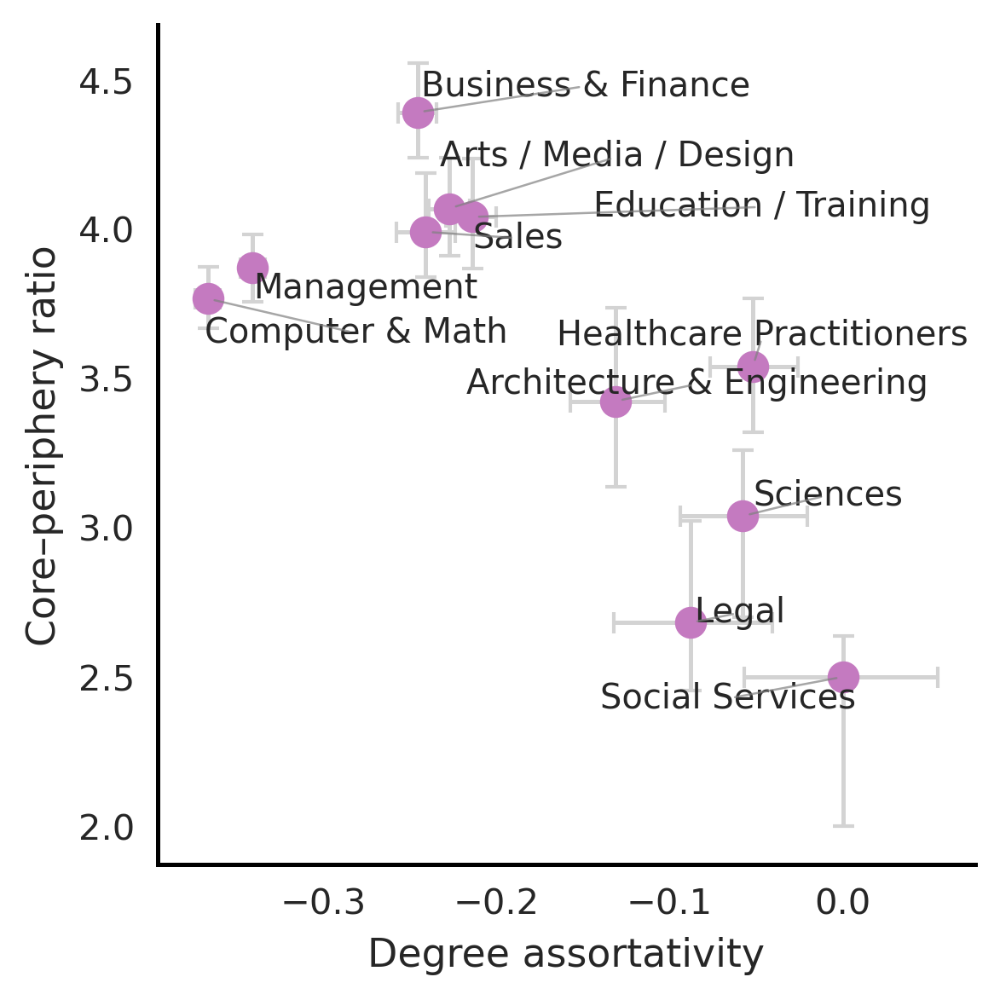

In [15]:
fig, ax = plt.subplots(figsize=(4, 4))

ax.errorbar(
    assort_mean,
    core_mean,
    xerr=assort_err,
    yerr=core_err,
    fmt="o",
    markersize=8,
    ecolor="lightgray",
    capsize=3,
    color="#C47AC0",
    alpha=1,
)

# --- Add text labels using adjustText ---
texts = []
for x, y, label in zip(assort_mean, core_mean, fields):
    t = ax.text(x, y, label)
    texts.append(t)

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.6, alpha=0.7),

    # Make labels push away harder
    force_text=2.5,  

    # Increase minimum padding around labels
    expand_text=(1.6, 1.6),
    expand_points=(2.0, 2.0),

    # Increase iteration count for more stable separation
    iterations=200, 

    # Make the labels repel each other more strongly
    force_points=1.5,
    force_explode=1.2,

    # Let labels move both horizontally and vertically
    only_move={'points': 'xy', 'text': 'xy'}
)


ax.set_xlabel("Degree assortativity")
ax.set_ylabel("Core–periphery ratio")

# Grid aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [16]:
cbsa = load_cbsa()


In [17]:
counties=counties.merge(cbsa[['CBSA Code', 'CBSA Title', 'STCOFIPS']], on='STCOFIPS', how='left')

cbsa_gdf = counties.dissolve(
    by='CBSA Code',
    as_index=False
)

cbsa_gdf=cbsa_gdf.drop(columns=['name'])
cbsa_gdf=cbsa_gdf.rename(columns={'CBSA Title':'name', 'CBSA Code':'CBSA'})

In [18]:
cbsa_gdf = cbsa_gdf.to_crs("EPSG:5070")
cbsa_gdf["x"] = cbsa_gdf.geometry.centroid.x
cbsa_gdf["y"] = cbsa_gdf.geometry.centroid.y

coords = cbsa_gdf.set_index("CBSA")[["x", "y"]]


edges_irs = flows_irs_all.merge(
    coords, left_on="CBSA Code", right_index=True
).rename(columns={"x": "x1", "y": "y1"})

edges_irs = edges_irs.merge(
    coords, left_on="CBSA Code_next", right_index=True
).rename(columns={"x": "x2", "y": "y2"})


norm_irs = LogNorm(
    vmin=edges_irs["n"].quantile(0.5),
    vmax=edges_irs["n"].quantile(0.999)
)

cmap = plt.cm.plasma   # PURPLE→YELLOW glow

edges_irs_filtered=edges_irs[edges_irs['n']>=edges_irs["n"].quantile(0.5)]
edges_irs_sorted = edges_irs_filtered.sort_values('n')


edges_exp = flows_exp_all.merge(
    coords, left_on="CBSA Code", right_index=True
).rename(columns={"x": "x1", "y": "y1"})

edges_exp = edges_exp.merge(
    coords, left_on="CBSA Code_next", right_index=True
).rename(columns={"x": "x2", "y": "y2"})

norm_exp = LogNorm(
    vmin=edges_exp["n"].quantile(0.5),
    vmax=edges_exp["n"].quantile(0.999)
)

cmap = plt.cm.plasma   # PURPLE→YELLOW glow

edges_exp_filtered=edges_exp[edges_exp['n']>=edges_exp["n"].quantile(0.5)]
edges_exp_sorted = edges_exp_filtered.sort_values('n')

smap = mpl.cm.ScalarMappable(norm=norm_irs, cmap=cmap)

In [19]:
# no Alaska, no Hawaii

# cbsa codes for alaska and hawaii

cbsa_ak_hi = [
    11260,  # anchorage, ak
    21820,  # fairbanks, ak
    27940,  # juneau, ak
    16220,  # kenai, ak
    28540,  # ketchikan, ak
    46520,  # urban honolulu, hi
    27980,  # kahului-wailuku-lahaina, hi
    25900,  # hilo, hi
    28180   # kapaa, hi
]
cbsa_ak_hi = [str(x) for x in cbsa_ak_hi]

edges_irs_sorted=edges_irs_sorted[~(edges_irs_sorted['CBSA Code'].isin(cbsa_ak_hi))&~(edges_irs_sorted['CBSA Code_next'].isin(cbsa_ak_hi))]
edges_exp_sorted=edges_exp_sorted[~(edges_exp_sorted['CBSA Code'].isin(cbsa_ak_hi))&~(edges_exp_sorted['CBSA Code_next'].isin(cbsa_ak_hi))]

In [20]:
edges_exp["dist"] = np.hypot(edges_exp["x2"] - edges_exp["x1"],
                             edges_exp["y2"] - edges_exp["y1"])

edges_irs["dist"] = np.hypot(edges_irs["x2"] - edges_irs["x1"],
                             edges_irs["y2"] - edges_irs["y1"])

def stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

# HIGH-SKILL / EXP
X_exp = sm.add_constant(np.log(edges_exp["dist"]))
y_exp = np.log(edges_exp["n"])
res_exp = sm.OLS(y_exp, X_exp).fit()

beta_exp = res_exp.params["dist"]
p_exp = res_exp.pvalues["dist"]
beta_exp_fmt = f"{beta_exp:.2f}{stars(p_exp)}"

# REGULAR / IRS
X_irs = sm.add_constant(np.log(edges_irs["dist"]))
y_irs = np.log(edges_irs["n"])
res_irs = sm.OLS(y_irs, X_irs).fit()

beta_irs = res_irs.params["dist"]
p_irs = res_irs.pvalues["dist"]
beta_irs_fmt = f"{beta_irs:.2f}{stars(p_irs)}"

print("High-skill distance decay β =", beta_exp_fmt)
print("Regular distance decay β   =", beta_irs_fmt)

# high-skill CI
ci_exp = res_exp.conf_int().loc["dist"]
ci_exp_low, ci_exp_high = ci_exp

# regular CI
ci_irs = res_irs.conf_int().loc["dist"]
ci_irs_low, ci_irs_high = ci_irs

print(f"High-skill β = {beta_exp:.2f} [{ci_exp_low:.2f}, {ci_exp_high:.2f}]")
print(f"Regular β   = {beta_irs:.2f} [{ci_irs_low:.2f}, {ci_irs_high:.2f}]")

High-skill distance decay β = 0.01
Regular distance decay β   = -0.37***
High-skill β = 0.01 [-0.01, 0.02]
Regular β   = -0.37 [-0.38, -0.35]


### For SI: PPML gravity robustness check

Equation above is estimated as `log(n) ~ const + log(dist)` on the sparse edge list of realised CBSA-to-CBSA flows only. Because the outcome is log-transformed, every zero-flow origin–destination pair is dropped from the estimation sample by construction (`log(0)` is undefined). Zero flows are therefore excluded, and the resulting estimate is conditional on a pair having any flow at all.

We test the sensitivity of the distance-decay estimate to this choice with a PPML (Poisson pseudo-maximum-likelihood) specification, which is defined at zero and lets us retain the full dyad population: first without fixed effects (isolating the effect of adding zeros alone), then with origin and destination fixed effects - the standard "Log of Gravity" fix (Silva & Tenreyro, 2006), which also absorbs any origin/destination mass or size effects. PPML standard errors are bilaterally clustered by origin and destination (two-way clustering).

In [21]:
from utils import ppml_distance_decay_check

cmp_exp, grid_exp = ppml_distance_decay_check(
    edges_exp, "CBSA Code", "CBSA Code_next", coords, res_exp, label="High-skill (exp)"
)
print()
cmp_irs, grid_irs = ppml_distance_decay_check(
    edges_irs, "CBSA Code", "CBSA Code_next", coords, res_irs, label="General mobility (irs)"
)

/mnt/sdb1/timur/anaconda3/envs/phd_work/lib/python3.12/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 61849 observations removed because of separation.
  warnings.warn(


High-skill (exp): 770,006 possible ordered pairs; 22,786 have nonzero flow -> 97.0% of dyads are zero-flow and excluded from spec (A) by construction of log(F).
                                                                              spec  beta_log_dist       se        p    ci_low   ci_high      n
                                    (A) OLS log-log, zeros dropped [existing spec]       0.007034 0.006823 0.302551 -0.006339  0.020407  22786
                           (B) PPML, zeros retained, no FE, bilateral-clustered SE      -0.262195 0.063486 0.000036 -0.386626 -0.137765 770006
(C) PPML, zeros retained, O+D FE, bilateral-clustered SE [reviewer-requested spec]      -0.525622 0.060291 0.000000 -0.643790 -0.407454 708157

General mobility (irs): 771,762 possible ordered pairs; 36,892 have nonzero flow -> 95.2% of dyads are zero-flow and excluded from spec (A) by construction of log(F).
                                                                              spec  beta_log_dist  

N in spec (C) is below the possible dyad count because `pyfixest` drops dyads and fixed-effect levels subject to perfect separation, which is standard for HDFE Poisson estimation. Standard errors in specs (B) and (C) are bilaterally clustered by origin and destination.

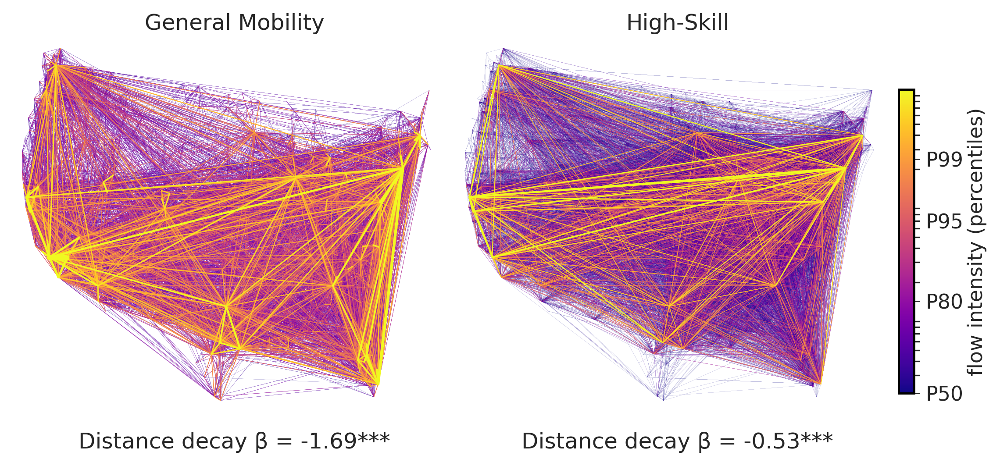

In [22]:
xmin, xmax = -2400000, 2400000
ymin, ymax =     0,   3200000

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plt.subplots_adjust(wspace=0.0)

for _, row in edges_irs_sorted.iterrows():
    w = row["n"]

    axes[0].plot(
        [row.x1, row.x2],
        [row.y1, row.y2],
        color=cmap(norm_irs(row.n)),
        alpha=1,
        linewidth=0.02 + 0.0015 * (w ** 0.55),
        zorder=1,
        clip_on=True
    )

for _, row in edges_exp_sorted.iterrows():
    w = row["n"]

    axes[1].plot(
        [row.x1, row.x2],
        [row.y1, row.y2],
        color=cmap(norm_exp(row.n)),
        alpha=1,
        linewidth=0.02 + 0.015 * (w ** 0.55),
        zorder=1,
        clip_on=True
    )

for ax in axes:
    ax.autoscale(enable=False)

for ax in axes:
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_axis_off()

# PPML with origin+destination fixed effects (spec C) is the preferred,
# zero-inclusive distance-decay specification (see SI robustness table);
# annotate the figure with these estimates rather than the naive OLS ones.
fe_exp = cmp_exp.loc[cmp_exp["spec"].str.contains("O+D FE", regex=False)].iloc[0]
fe_irs = cmp_irs.loc[cmp_irs["spec"].str.contains("O+D FE", regex=False)].iloc[0]

beta_exp_fe_fmt = f"{fe_exp['beta_log_dist']:.2f}{stars(fe_exp['p'])}"
beta_irs_fe_fmt = f"{fe_irs['beta_log_dist']:.2f}{stars(fe_irs['p'])}"

axes[0].text(
    0.5, 0.03,
    f"Distance decay β = {beta_irs_fe_fmt}",
    ha="center", va="top", fontsize=12,
    transform=axes[0].transAxes
)

axes[1].text(
    0.5, 0.03,
    f"Distance decay β = {beta_exp_fe_fmt}",
    ha="center", va="top", fontsize=12,
    transform=axes[1].transAxes
)

axes[0].set_title("General Mobility", pad=5)
axes[1].set_title("High-Skill", pad=5)

### Colorbar (placed outside the subplots)
cbar = fig.colorbar(
    smap,
    ax=axes.ravel().tolist(),   # attach to whole figure
    orientation='vertical',
    fraction=0.035,             # small vertical bar
    pad=0,                    # spacing between bar and plots
    shrink=0.75
)

quantiles = [0.50, 0.80, 0.95, 0.99]
quantile_vals = [edges_irs["n"].quantile(q) for q in quantiles]

cbar.set_ticks(quantile_vals)
cbar.set_ticklabels([f"P{int(q*100)}" for q in quantiles])

for lbl in cbar.ax.get_yticklabels():
    lbl.set_rotation(0)
    lbl.set_fontsize(11)

cbar.set_label("flow intensity (percentiles)", labelpad=2)


plt.show()

### For SI: identical-CBSA-set check

The comparison above estimates each network on its own node coverage, and the high-skill and general-mobility networks do not necessarily span the same CBSAs, so part of the high-skill/general contrast could come from differing coverage rather than from distance sensitivity. Here both networks are restricted to their shared CBSA set, and the OLS bridge model and the PPML fits (no FE, and origin plus destination FE, bilateral-clustered SEs) are re-estimated on the zero-inclusive dyad grid built from that same node set.

In [23]:
from utils import ppml_distance_decay_common_nodes

cmp_common = ppml_distance_decay_common_nodes(
    edges_exp, edges_irs, "CBSA Code", "CBSA Code_next", coords,
    label_a="High-skill (exp)", label_b="General mobility (irs)"
)

Shared node set: 878 nodes (878 in High-skill (exp), 879 in General mobility (irs)).


/mnt/sdb1/timur/anaconda3/envs/phd_work/lib/python3.12/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 61849 observations removed because of separation.
  warnings.warn(


               network                                                     spec  beta_log_dist       se        p    ci_low   ci_high      n  pct_zero
      High-skill (exp)       (A) OLS log-log, zeros dropped, common-node bridge       0.007034 0.006823 0.302551 -0.006339  0.020407  22786 97.040802
      High-skill (exp)  (B) PPML, zeros retained, no FE, bilateral-clustered SE      -0.262195 0.063486 0.000036 -0.386626 -0.137765 770006 97.040802
      High-skill (exp) (C) PPML, zeros retained, O+D FE, bilateral-clustered SE      -0.525622 0.060291 0.000000 -0.643790 -0.407454 708157 97.040802
General mobility (irs)       (A) OLS log-log, zeros dropped, common-node bridge      -0.365956 0.007888 0.000000 -0.381416 -0.350495  36883 95.210037
General mobility (irs)  (B) PPML, zeros retained, no FE, bilateral-clustered SE      -1.438905 0.075868 0.000000 -1.587603 -1.290207 770006 95.210037
General mobility (irs) (C) PPML, zeros retained, O+D FE, bilateral-clustered SE      -1.687222 0.088

### For SI: PageRank as an implied gravity destination effect

Writing the fitted flow from the PPML gravity model above as F̂_ij = exp(μ_i)·exp(ν_j)·d_ij^β, the transition probability w_ij/s_i^out takes the form of a competing-destinations choice probability, in which exp(ν_j), destination j's attractiveness net of distance and competing destinations, competes against every other destination reachable from i. Substituting into the PageRank recursion PR_j ∝ Σ_i PR_i·(w_ij/s_i^out) and collecting the j-independent terms into A_i = Σ_k exp(ν_k)·d_ik^β gives PR_j ∝ exp(ν_j)·Σ_i (PR_i/A_i)·d_ij^β. PageRank then factorises approximately into the gravity destination effect and an accessibility term describing how reachable j is from the rest of the network, weighted by each origin's own centrality.

Two checks follow. First, since log(PR_j) ≈ ν_j + log(accessibility_j), log(PR_j) is regressed on ν_j alone, leaving accessibility in the residual. Second, observed flows are replaced by the gravity model's fitted flows, PageRank is recomputed on that network and correlated with the observed PageRank. The second check is repeated with the 50 highest-PageRank CBSAs excluded from each network.

Both checks use the gravity model's own fitted values, so they test the PageRank/gravity link internally and are not an out-of-sample validation of the gravity model.

In [24]:
from utils import pagerank_gravity_factorisation_check

r_exp = pagerank_gravity_factorisation_check(grid_exp, hits_exp_all, label="High-skill (exp)")
print()
r_irs = pagerank_gravity_factorisation_check(grid_irs, hits_irs_all, label="General mobility (irs)")
print()
pd.DataFrame([r_exp, r_irs])

/mnt/sdb1/timur/anaconda3/envs/phd_work/lib/python3.12/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 61849 observations removed because of separation.
  warnings.warn(


High-skill (exp): R^2(log PageRank ~ destination FE alone) = 0.853 (n=805)
High-skill (exp): R^2(log real PR, log gravity-implied PR) = 0.989, Spearman rho = 0.964 (n=806)
High-skill (exp): same R^2 excluding top 50 PageRank nodes = 0.967

General mobility (irs): R^2(log PageRank ~ destination FE alone) = 0.838 (n=805)
General mobility (irs): R^2(log real PR, log gravity-implied PR) = 0.920, Spearman rho = 0.911 (n=806)
General mobility (irs): same R^2 excluding top 50 PageRank nodes = 0.845



,label,beta_log_dist,n_destination_fe,r2_destination_fe,n_gravity_pagerank,r2_gravity_pagerank,spearman_gravity_pagerank,r2_gravity_pagerank_excl_top50
0,High-skill (exp),-0.525622,805,0.852538,806,0.989255,0.964448,0.967322
1,General mobility (irs),-1.687420,805,0.837721,806,0.919593,0.911488,0.845174


### Counties

In [24]:
hits_exp_all = pd.read_parquet("../data_generated/network_metrics/hits_exp_1122.parquet")
flows_exp_all = pd.read_parquet("../data_generated/network_metrics/flows_exp_1122.parquet")

hits_irs_all = pd.read_parquet("../data_generated/network_metrics/hits_irs_1122.parquet")
flows_irs_all = pd.read_parquet("../data_generated/network_metrics/flows_irs_1122.parquet")

In [25]:
counties = counties.to_crs("EPSG:5070")
counties["x"] = counties.geometry.centroid.x
counties["y"] = counties.geometry.centroid.y

coords = counties.set_index("STCOFIPS")[["x", "y"]]


edges_irs = flows_irs_all.merge(
    coords, left_on="STCOFIPS", right_index=True
).rename(columns={"x": "x1", "y": "y1"})

edges_irs = edges_irs.merge(
    coords, left_on="STCOFIPS_next", right_index=True
).rename(columns={"x": "x2", "y": "y2"})


norm_irs = LogNorm(
    vmin=edges_irs["n"].quantile(0.5),
    vmax=edges_irs["n"].quantile(0.999)
)

cmap = plt.cm.plasma   # PURPLE→YELLOW glow

edges_irs_filtered=edges_irs[edges_irs['n']>=edges_irs["n"].quantile(0.5)]
edges_irs_sorted = edges_irs_filtered.sort_values('n')


edges_exp = flows_exp_all.merge(
    coords, left_on="STCOFIPS", right_index=True
).rename(columns={"x": "x1", "y": "y1"})

edges_exp = edges_exp.merge(
    coords, left_on="STCOFIPS_next", right_index=True
).rename(columns={"x": "x2", "y": "y2"})

norm_exp = LogNorm(
    vmin=edges_exp["n"].quantile(0.5),
    vmax=edges_exp["n"].quantile(0.999)
)

cmap = plt.cm.plasma   # PURPLE→YELLOW glow

edges_exp_filtered=edges_exp[edges_exp['n']>=edges_exp["n"].quantile(0.5)]
edges_exp_sorted = edges_exp_filtered.sort_values('n')

smap = mpl.cm.ScalarMappable(norm=norm_irs, cmap=cmap)

In [26]:
# no Alaska, no Hawaii

edges_irs_sorted=edges_irs_sorted[~(edges_irs_sorted.STCOFIPS.str.startswith(('02', '15')))&~(edges_irs_sorted.STCOFIPS_next.str.startswith(('02', '15')))]
edges_exp_sorted=edges_exp_sorted[~(edges_exp_sorted.STCOFIPS.str.startswith(('02', '15')))&~(edges_exp_sorted.STCOFIPS_next.str.startswith(('02', '15')))]

In [27]:
edges_exp["dist"] = np.hypot(edges_exp["x2"] - edges_exp["x1"],
                             edges_exp["y2"] - edges_exp["y1"])

edges_irs["dist"] = np.hypot(edges_irs["x2"] - edges_irs["x1"],
                             edges_irs["y2"] - edges_irs["y1"])

# HIGH-SKILL / EXP
X_exp = sm.add_constant(np.log(edges_exp["dist"]))
y_exp = np.log(edges_exp["n"])
res_exp = sm.OLS(y_exp, X_exp).fit()

beta_exp = res_exp.params["dist"]
p_exp = res_exp.pvalues["dist"]
beta_exp_fmt = f"{beta_exp:.2f}{stars(p_exp)}"

# REGULAR / IRS
X_irs = sm.add_constant(np.log(edges_irs["dist"]))
y_irs = np.log(edges_irs["n"])
res_irs = sm.OLS(y_irs, X_irs).fit()

beta_irs = res_irs.params["dist"]
p_irs = res_irs.pvalues["dist"]
beta_irs_fmt = f"{beta_irs:.2f}{stars(p_irs)}"

print("High-skill distance decay β =", beta_exp_fmt)
print("Regular distance decay β   =", beta_irs_fmt)

High-skill distance decay β = -0.03***
Regular distance decay β   = -0.37***


### For SI: PPML gravity robustness check, county level

Same as the CBSA-level section above. Repeated here using the county-to-county flow tables and centroid distances built above.

In [28]:
from utils import ppml_distance_decay_check

cmp_exp, grid_exp = ppml_distance_decay_check(
    edges_exp, "STCOFIPS", "STCOFIPS_next", coords, res_exp, label="High-skill (exp)"
)
print()
cmp_irs, grid_irs = ppml_distance_decay_check(
    edges_irs, "STCOFIPS", "STCOFIPS_next", coords, res_irs, label="General mobility (irs)"
)

/mnt/sdb1/timur/anaconda3/envs/phd_work/lib/python3.12/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 949140 observations removed because of separation.
  warnings.warn(


High-skill (exp): 4,445,772 possible ordered pairs; 48,181 have nonzero flow -> 98.9% of dyads are zero-flow and excluded from spec (A) by construction of log(F).
                                                                              spec  beta_log_dist       se            p    ci_low   ci_high       n
                                    (A) OLS log-log, zeros dropped [existing spec]      -0.034235 0.003445 3.002636e-23 -0.040987 -0.027483   48181
                           (B) PPML, zeros retained, no FE, bilateral-clustered SE      -0.745763 0.066759 0.000000e+00 -0.876609 -0.614918 4445772
(C) PPML, zeros retained, O+D FE, bilateral-clustered SE [reviewer-requested spec]      -0.594559 0.045710 0.000000e+00 -0.684150 -0.504969 3496632



/mnt/sdb1/timur/anaconda3/envs/phd_work/lib/python3.12/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 14746 observations removed because of separation.
  warnings.warn(


General mobility (irs): 4,445,772 possible ordered pairs; 97,807 have nonzero flow -> 97.8% of dyads are zero-flow and excluded from spec (A) by construction of log(F).
                                                                              spec  beta_log_dist       se   p    ci_low   ci_high       n
                                    (A) OLS log-log, zeros dropped [existing spec]      -0.370744 0.003879 0.0 -0.378347 -0.363142   97807
                           (B) PPML, zeros retained, no FE, bilateral-clustered SE      -1.797430 0.054485 0.0 -1.904219 -1.690642 4445772
(C) PPML, zeros retained, O+D FE, bilateral-clustered SE [reviewer-requested spec]      -1.879929 0.062754 0.0 -2.002923 -1.756934 4431026


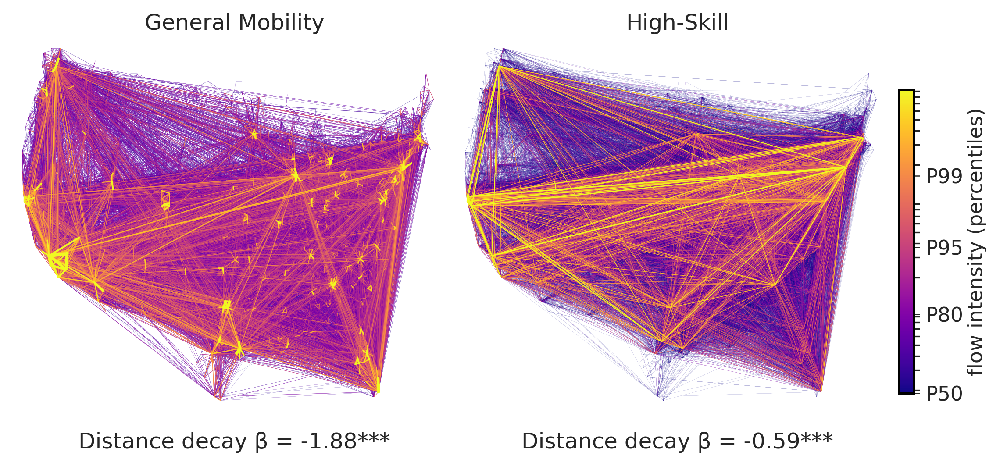

In [29]:
xmin, xmax = -2400000, 2400000
ymin, ymax =     0,   3200000

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plt.subplots_adjust(wspace=0.0)

for _, row in edges_irs_sorted.iterrows():
    w = row["n"]

    axes[0].plot(
        [row.x1, row.x2],
        [row.y1, row.y2],
        color=cmap(norm_irs(row.n)),
        alpha=1,
        linewidth=0.02 + 0.0015 * (w ** 0.55),
        zorder=1,
        clip_on=True
    )

for _, row in edges_exp_sorted.iterrows():
    w = row["n"]

    axes[1].plot(
        [row.x1, row.x2],
        [row.y1, row.y2],
        color=cmap(norm_exp(row.n)),
        alpha=1,
        linewidth=0.02 + 0.015 * (w ** 0.55),
        zorder=1,
        clip_on=True
    )

for ax in axes:
    ax.autoscale(enable=False)

for ax in axes:
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_axis_off()

# PPML with origin+destination fixed effects (spec C) is the preferred,
# zero-inclusive distance-decay specification (see SI robustness table);
# annotate the figure with these estimates rather than the naive OLS ones.
fe_exp = cmp_exp.loc[cmp_exp["spec"].str.contains("O+D FE", regex=False)].iloc[0]
fe_irs = cmp_irs.loc[cmp_irs["spec"].str.contains("O+D FE", regex=False)].iloc[0]

beta_exp_fe_fmt = f"{fe_exp['beta_log_dist']:.2f}{stars(fe_exp['p'])}"
beta_irs_fe_fmt = f"{fe_irs['beta_log_dist']:.2f}{stars(fe_irs['p'])}"

axes[0].text(
    0.5, 0.03,
    f"Distance decay β = {beta_irs_fe_fmt}",
    ha="center", va="top", fontsize=12,
    transform=axes[0].transAxes
)

axes[1].text(
    0.5, 0.03,
    f"Distance decay β = {beta_exp_fe_fmt}",
    ha="center", va="top", fontsize=12,
    transform=axes[1].transAxes
)

axes[0].set_title("General Mobility", pad=5)
axes[1].set_title("High-Skill", pad=5)

### Colorbar (placed outside the subplots)
cbar = fig.colorbar(
    smap,
    ax=axes.ravel().tolist(),   # attach to whole figure
    orientation='vertical',
    fraction=0.035,             # small vertical bar
    pad=0,                    # spacing between bar and plots
    shrink=0.75
)

quantiles = [0.50, 0.80, 0.95, 0.99]
quantile_vals = [edges_irs["n"].quantile(q) for q in quantiles]

cbar.set_ticks(quantile_vals)
cbar.set_ticklabels([f"P{int(q*100)}" for q in quantiles])

for lbl in cbar.ax.get_yticklabels():
    lbl.set_rotation(0)
    lbl.set_fontsize(11)

cbar.set_label("flow intensity (percentiles)", labelpad=2)


plt.show()

## PANEL 2

### County

In [30]:
hits_exp_all = pd.read_parquet("../data_generated/network_metrics/hits_exp_1122_lodes.parquet")
flows_exp_all = pd.read_parquet("../data_generated/network_metrics/flows_exp_1122_lodes.parquet")

hits_irs_all = pd.read_parquet("../data_generated/network_metrics/hits_irs_1122_lodes.parquet")
flows_irs_all = pd.read_parquet("../data_generated/network_metrics/flows_irs_1122_lodes.parquet")

In [31]:
hits_merged=hits_exp_all.merge(hits_irs_all, on='STCOFIPS', how='inner', suffixes=('_exp', '_irs'))

In [32]:
hits_merged['pagerank_exp'].sum()

0.9992840649242449

In [33]:
# Extract both pagerank series
df = hits_merged[['pagerank_exp', 'pagerank_irs']].copy()

df = df.dropna(subset=['pagerank_exp', 'pagerank_irs'])

exp_sorted = np.sort(df['pagerank_exp'])[::-1]
irs_sorted = np.sort(df['pagerank_irs'])[::-1]

ranks_exp = np.arange(1, len(exp_sorted) + 1)
ranks_irs = np.arange(1, len(irs_sorted) + 1)

gini_exp = gini(hits_merged["pagerank_exp"])
gini_irs = gini(hits_merged["pagerank_irs"])

print(gini_exp)
print(gini_irs)


0.7535794438176078
0.5406851587183508


In [34]:
pr_exp_sorted, pr_exp_ccdf = compute_ccdf(df['pagerank_exp'].values)
pr_irs_sorted, pr_irs_ccdf = compute_ccdf(df['pagerank_irs'].values)

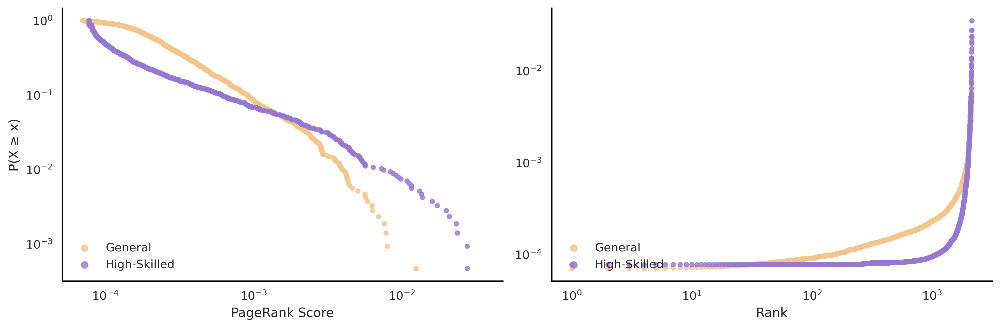

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12,4), sharey=False)

# ---------------------------------
# 1. PAGERANK (ABSOLUTE VALUES)
# ---------------------------------
ax = axes[0]

ax.scatter(
    pr_irs_sorted, pr_irs_ccdf,
    s=14, alpha=0.8, color='#f2c68b', label="General"
)

ax.scatter(
    pr_exp_sorted, pr_exp_ccdf,
    s=14, alpha=0.8, color='#9678d1', label="High-Skilled"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("PageRank Score")
ax.set_ylabel("P(X ≥ x)")
ax.set_title("")

ax.legend(frameon=False, loc='lower left', markerscale=1.5)

# Aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis='both', which='both', length=5)


# ---------------------------------
# 2. PAGERANK RANKS (OPTIONAL SECOND PANEL)
# ---------------------------------
# Equivalent to your idea with ranks_exp / ranks_irs
ax = axes[1]

ranks_exp = np.arange(1, len(pr_exp_sorted)+1)
ranks_irs = np.arange(1, len(pr_irs_sorted)+1)

ax.scatter(
    ranks_irs, pr_irs_sorted,
    s=14, alpha=0.8, color='#f2c68b', label="General"
)

ax.scatter(
    ranks_exp, pr_exp_sorted,
    s=14, alpha=0.8, color='#9678d1', label="High-Skilled"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Rank")
ax.set_title("")

ax.legend(frameon=False, loc='lower left', markerscale=1.5)

# Aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis='both', which='both', length=5)

plt.tight_layout()
plt.show()

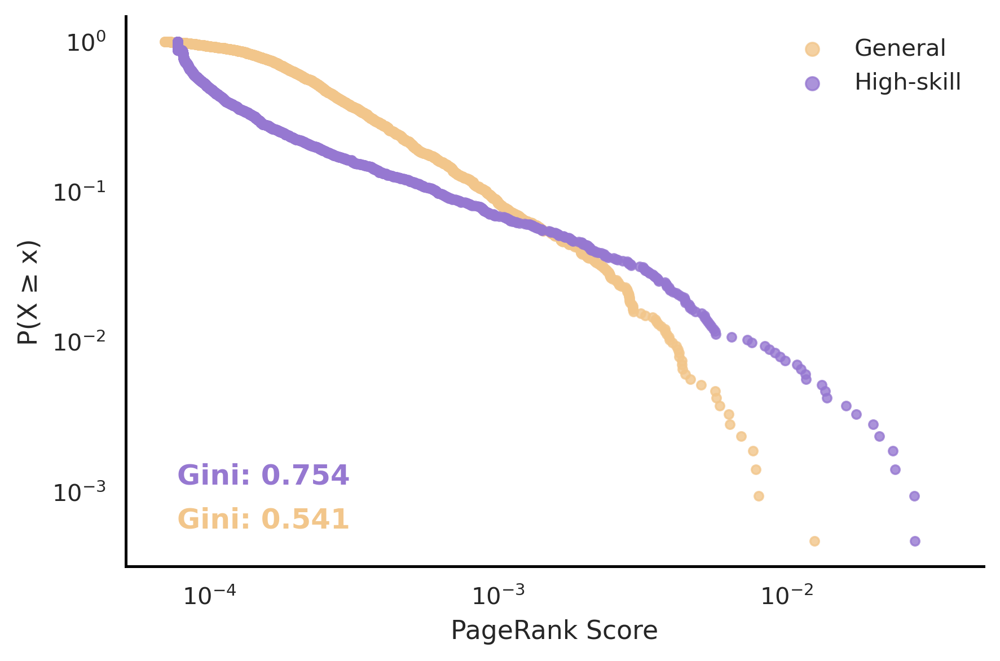

In [36]:
fig, axes = plt.subplots(1, 1, figsize=(6,4))

# ---------------------------------
# 1. PAGERANK (ABSOLUTE VALUES)
# ---------------------------------
ax = axes

ax.scatter(
    pr_irs_sorted, pr_irs_ccdf,
    s=14, alpha=0.8, color='#f2c68b', label="General"
)

ax.scatter(
    pr_exp_sorted, pr_exp_ccdf,
    s=14, alpha=0.8, color='#9678d1', label="High-skill"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("PageRank Score")
ax.set_ylabel("P(X ≥ x)")
ax.set_title("")

ax.legend(frameon=False, loc='upper right', markerscale=1.5)

# Aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis='both', which='both', length=5)

# Add Gini coefficients as text
ax.text(
    0.06, 0.15,
    f"Gini: {gini_exp:.3f}",
    weight="semibold",
    transform=ax.transAxes,
    color="#9678d1",
    fontsize=12,
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.8,
        pad=3
    )
)

ax.text(
    0.06, 0.07,
    f"Gini: {gini_irs:.3f}",
    weight="semibold",
    transform=ax.transAxes,
    color="#f2c68b",
    fontsize=12,
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.8,
        pad=3
    )
)


plt.tight_layout()
plt.show()

In [37]:
hits_merged = classify_per_window(df=hits_merged, centrality="pagerank", log_fn=np.log10)

In [38]:
# Extreme PuOr (higher contrast)
colors_strong = [
    "#7f3b08",   # very deep burnt orange
    "#f2c68b",   # soft orange
    "#fcead6",   # very light near-white
    "#9678d1",   # strong lavender/purple
    "#3f007d"    # very deep purple
]

strong_puor = mcolors.LinearSegmentedColormap.from_list(
    "StrongPuOr", colors_strong, N=256
)

# Example normalization (center = 0)
norm = mcolors.TwoSlopeNorm(vmin=hits_merged["d"].min(),
                            vcenter=0,
                            vmax=1)

In [39]:
counties=counties.merge(hits_merged[['STCOFIPS', 'd']], on='STCOFIPS', how='left')

counties["color"] = [
    tuple(strong_puor(norm(v))) if pd.notnull(v) else np.nan
    for v in counties["d"]
]

In [40]:
# Top 5 brain hubs (highest d)
brain_hubs = counties.sort_values("d", ascending=False).head(7)

# Top 5 mass hubs (lowest d)
mass_hubs = counties.sort_values("d", ascending=True).head(7)

print("Brain hubs:\n", brain_hubs[["STCOFIPS","name","d"]])
print("\nMass hubs:\n", mass_hubs[["STCOFIPS","name","d"]])

Brain hubs:
      STCOFIPS               name         d
1260    06075  San Francisco, CA  0.985762
47      06081      San Mateo, CA  0.968610
48      06085    Santa Clara, CA  0.927830
37      06001        Alameda, CA  0.773526
1036    53033           King, WA  0.617989
40      06013   Contra Costa, CA  0.608824
2979    48491     Williamson, TX  0.561523

Mass hubs:
      STCOFIPS                name         d
1256    13063         Clayton, GA -0.966707
366     29031  Cape Girardeau, MO -0.965113
1906    20061           Geary, KS -0.926889
2695    48375          Potter, TX -0.924138
2820    19193        Woodbury, IA -0.910776
1230    04021           Pinal, AZ -0.905248
2220    54079          Putnam, WV -0.903433


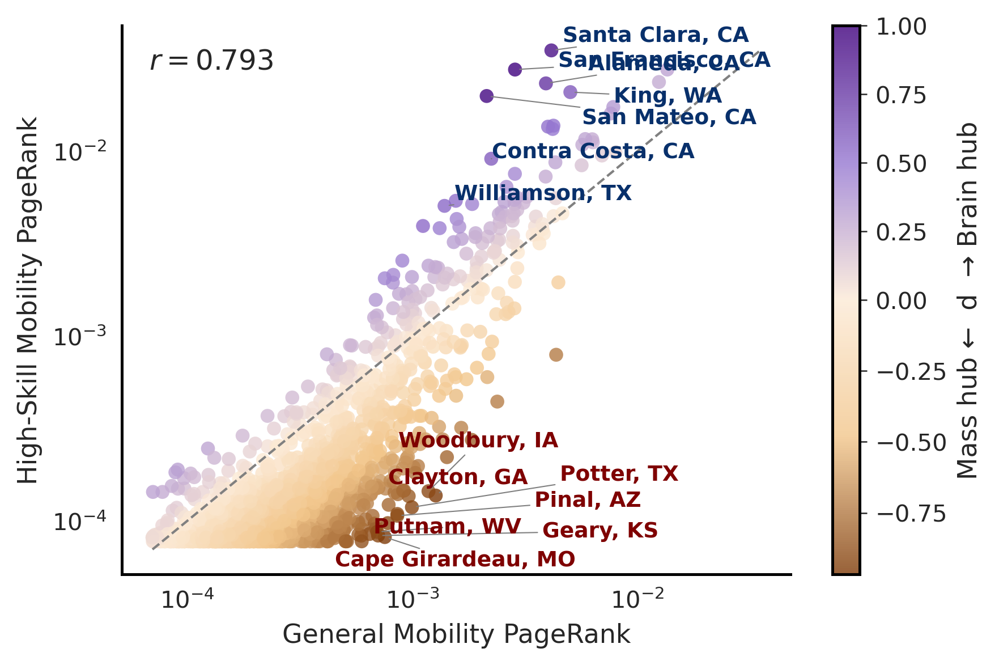

In [41]:
exp = hits_merged["pagerank_exp"]
irs = hits_merged["pagerank_irs"]

r, pval = pearsonr(irs, exp)
label = fr"$r = {r:.3f}$"

fig, ax = plt.subplots(figsize=(6,4))

sc = ax.scatter(
    irs, exp,
    c=hits_merged["d"], cmap=strong_puor,
    norm=norm,
    s=35, edgecolor="none", alpha=0.8
)

# Diagonal reference
lims = [min(exp.min(), irs.min()), max(exp.max(), irs.max())]
ax.plot(lims, lims, "--", color="gray", linewidth=1)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("General Mobility PageRank")
ax.set_ylabel("High-Skill Mobility PageRank")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis='both')

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Mass hub ←  d  → Brain hub")

texts = []

# BRAIN hubs
for _, row in brain_hubs.iterrows():
    x = hits_merged.loc[hits_merged["STCOFIPS"] == row["STCOFIPS"], "pagerank_irs"].values[0]
    y = hits_merged.loc[hits_merged["STCOFIPS"] == row["STCOFIPS"], "pagerank_exp"].values[0]

    t = ax.text(
        x, y, row["name"],
        fontsize=9, weight="bold", color="#08306B"
    )
    texts.append(t)

# MASS hubs
for _, row in mass_hubs.iterrows():
    x = hits_merged.loc[hits_merged["STCOFIPS"] == row["STCOFIPS"], "pagerank_irs"].values[0]
    y = hits_merged.loc[hits_merged["STCOFIPS"] == row["STCOFIPS"], "pagerank_exp"].values[0]

    t = ax.text(
        x, y, row["name"],
        fontsize=9, weight="bold", color="#7F0000"
    )
    texts.append(t)

adjust_text(
    texts, 
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5)
)

# Pearson corr text
ax.text(
    0.04, 0.96,
    label,
    transform=ax.transAxes,
    fontsize=12,
    weight="bold",
    va="top",
    ha="left",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.8,
        pad=3
    )
)


plt.tight_layout()
plt.show()

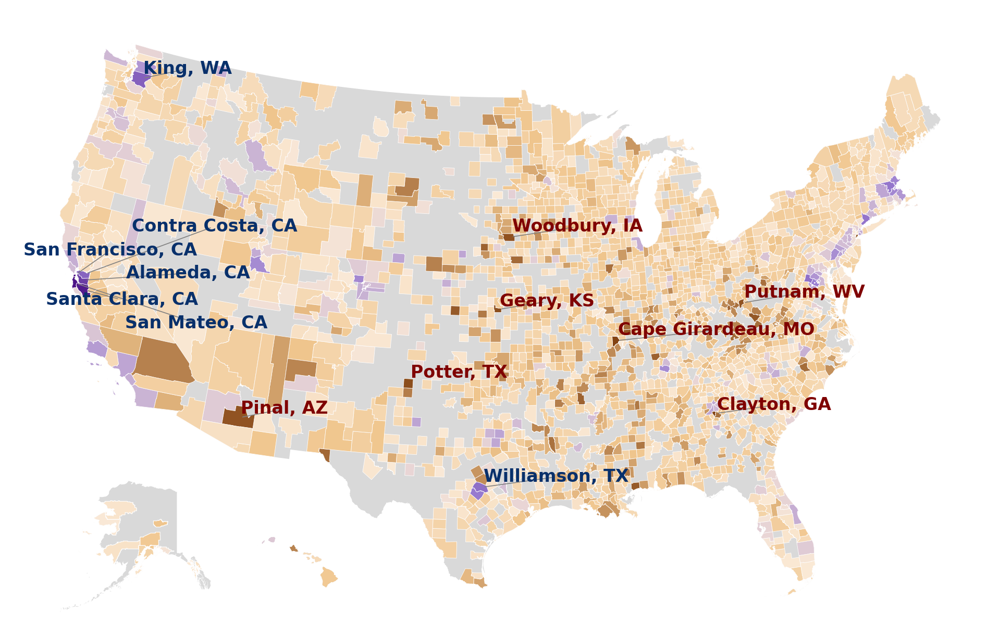

In [42]:
# -------------------------------------------------------
# Split counties into regions
# -------------------------------------------------------

not_conus=['02',  # Alaska
             '15',  # Hawaii
             '72',  # Puerto Rico
             '78',  # U.S. Virgin Islands
             '60',  # American Samoa
             '66',  # Guam
             '69']  # Northern Mariana Islands

usa = counties.to_crs("EPSG:5070") 
counties = counties.to_crs("EPSG:4269")

conus = usa[~usa["STATEFP"].isin(not_conus)]
alaska = counties[counties["STATEFP"] == "02"].copy()
hawaii = counties[counties["STATEFP"] == "15"].copy()

# Background polygons
conus_outline = conus[["geometry"]].dissolve()
alaska_outline = alaska[["geometry"]].dissolve()
hawaii_outline = hawaii[["geometry"]].dissolve()

conus=conus.dropna(subset='color')
alaska=alaska.dropna(subset='color')
hawaii=hawaii.dropna(subset='color')


# -------------------------------------------------------
# 1. Main CONUS map
# -------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))

# Background for CONUS as a single gray polygon
conus_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax,
    zorder=1
)

# Foreground county map
conus.plot(
    color=conus["color"],
    linewidth=0.2,
    edgecolor='white',
    ax=ax,
    legend=False,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"}
)

ax.axis("off")

# Identify the geodataframe rows for the hubs
brain_geo = conus[conus["STCOFIPS"].isin(brain_hubs["STCOFIPS"])]
mass_geo  = conus[conus["STCOFIPS"].isin(mass_hubs["STCOFIPS"])]

texts = []

# ----- Brain hubs: dark blue labels -----
for _, row in brain_geo.iterrows():
    x = row.geometry.centroid.x
    y = row.geometry.centroid.y
    t = ax.text(
        x, y, row["name"],
        fontsize=8, weight="bold",
        color="#08306B",      # dark blue
        zorder=10
    )
    texts.append(t)

# ----- Mass hubs: dark red labels -----
for _, row in mass_geo.iterrows():
    x = row.geometry.centroid.x
    y = row.geometry.centroid.y
    t = ax.text(
        x, y, row["name"],
        fontsize=8, weight="bold",
        color="#7F0000",      # dark red
        zorder=10
    )
    texts.append(t)

# Now adjust so labels don't overlap
adjust_text(
    texts, ax=ax,
    expand_points=(1.2, 1.2),
    expand_text=(1.2, 1.2),
    arrowprops=dict(arrowstyle="-", lw=0.4, color="gray"),
    force_points=0.5,
    force_text=0.7
)


# -------------------------------------------------------
# 2. ALASKA INSET
# -------------------------------------------------------
ax_ak = inset_axes(
    ax,
    width="75%", height="75%",   # size relative to main axes
    loc="lower left",
    bbox_to_anchor=(0.00, 0.00, 0.3, 0.3),  # fine-tune position
    bbox_transform=ax.transAxes
)

ax_ak.axis("off")

# Background for Alaska
alaska_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax_ak,
    zorder=1
)

# Alaska counties with pagerank
alaska.plot(
    color=alaska["color"],
    linewidth=0.3,
    edgecolor="white",
    ax=ax_ak,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"}
)

# Set xlim/ylim in EPSG:4269 coordinates (degrees)
ax_ak.set_xlim(-180, -129)
ax_ak.set_ylim(51, 72)


# -------------------------------------------------------
# 3. HAWAII INSET
# -------------------------------------------------------
ax_hi = inset_axes(
    ax, width="50%", height="50%", loc="lower left",
    bbox_to_anchor=(0.22, 0.02, 0.25, 0.25),  # position
    bbox_transform=ax.transAxes
)

ax_hi.set_axis_off()

hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi)
hawaii.plot(
    color=hawaii["color"],
    linewidth=0,
    ax=ax_hi,
    alpha=0.95,
    missing_kwds={"color": "none"}
)

ax_hi.set_xlim(-161, -154)
ax_hi.set_ylim(18, 23)

# # -------------------------------------------------------
# # 4. LEGEND
# # -------------------------------------------------------
# cbar = plt.colorbar(
#     sm,
#     ax=ax,
#     orientation="horizontal",
#     fraction=0.04,     # shrink vertically
#     pad=0.04            # distance from map
# )

# cbar.ax.tick_params(labelsize=10)
# cbar.set_label("High Skill Mobility Pagerank (log scale)", fontsize=12)


plt.show()

### CBSA

In [43]:
counties = load_counties()

In [44]:
hits_exp_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_exp_1122.parquet")
# flows_exp_all = pd.read_parquet("../data_generated/network_metrics/flows_exp_1122.parquet")

hits_irs_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_irs_1122.parquet")
# flows_irs_all = pd.read_parquet("../data_generated/network_metrics/flows_irs_1122.parquet")

cbsa = load_cbsa()


In [45]:
counties=counties.merge(cbsa[['CBSA Code', 'CBSA Title', 'STCOFIPS']], on='STCOFIPS', how='left')

cbsa_gdf = counties.dissolve(
    by='CBSA Code',
    as_index=False
)

cbsa_gdf=cbsa_gdf.drop(columns=['name'])
cbsa_gdf=cbsa_gdf.rename(columns={'CBSA Title':'name', 'CBSA Code':'CBSA'})

In [46]:
hits_merged=hits_exp_all.merge(hits_irs_all, on='CBSA', how='inner', suffixes=('_exp', '_irs'))

In [47]:
hits_merged['pagerank_exp'].sum()

0.9866452824030644

In [48]:
# Extract both pagerank series
df = hits_merged[['pagerank_exp', 'pagerank_irs']].copy()

df = df.dropna(subset=['pagerank_exp', 'pagerank_irs'])

exp_sorted = np.sort(df['pagerank_exp'])[::-1]
irs_sorted = np.sort(df['pagerank_irs'])[::-1]

ranks_exp = np.arange(1, len(exp_sorted) + 1)
ranks_irs = np.arange(1, len(irs_sorted) + 1)

gini_exp = gini(hits_merged["pagerank_exp"])
gini_irs = gini(hits_merged["pagerank_irs"])

print(gini_exp)
print(gini_irs)

0.774409265943316
0.5871661828904878


In [49]:
pr_exp_sorted, pr_exp_ccdf = compute_ccdf(df['pagerank_exp'].values)
pr_irs_sorted, pr_irs_ccdf = compute_ccdf(df['pagerank_irs'].values)

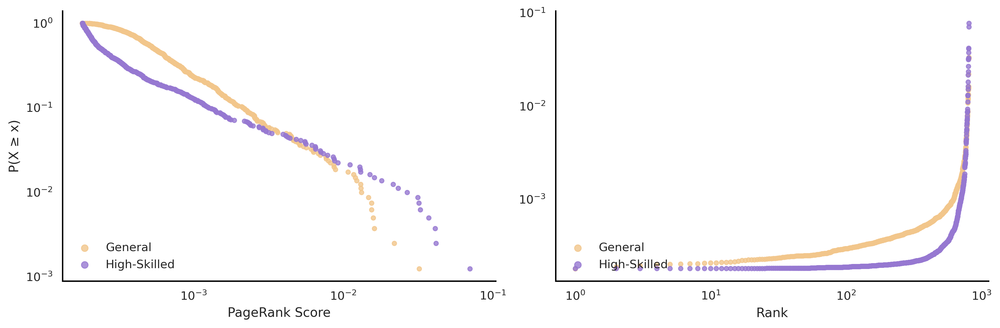

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12,4), sharey=False)

# ---------------------------------
# 1. PAGERANK (ABSOLUTE VALUES)
# ---------------------------------
ax = axes[0]

ax.scatter(
    pr_irs_sorted, pr_irs_ccdf,
    s=14, alpha=0.8, color='#f2c68b', label="General"
)

ax.scatter(
    pr_exp_sorted, pr_exp_ccdf,
    s=14, alpha=0.8, color='#9678d1', label="High-Skilled"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("PageRank Score")
ax.set_ylabel("P(X ≥ x)")
ax.set_title("")

ax.legend(frameon=False, loc='lower left', markerscale=1.5)

# Aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis='both', which='both', length=5)


# ---------------------------------
# 2. PAGERANK RANKS (OPTIONAL SECOND PANEL)
# ---------------------------------
# Equivalent to your idea with ranks_exp / ranks_irs
ax = axes[1]

ranks_exp = np.arange(1, len(pr_exp_sorted)+1)
ranks_irs = np.arange(1, len(pr_irs_sorted)+1)

ax.scatter(
    ranks_irs, pr_irs_sorted,
    s=14, alpha=0.8, color='#f2c68b', label="General"
)

ax.scatter(
    ranks_exp, pr_exp_sorted,
    s=14, alpha=0.8, color='#9678d1', label="High-Skilled"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Rank")
ax.set_title("")

ax.legend(frameon=False, loc='lower left', markerscale=1.5)

# Aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis='both', which='both', length=5)

plt.tight_layout()
plt.show()

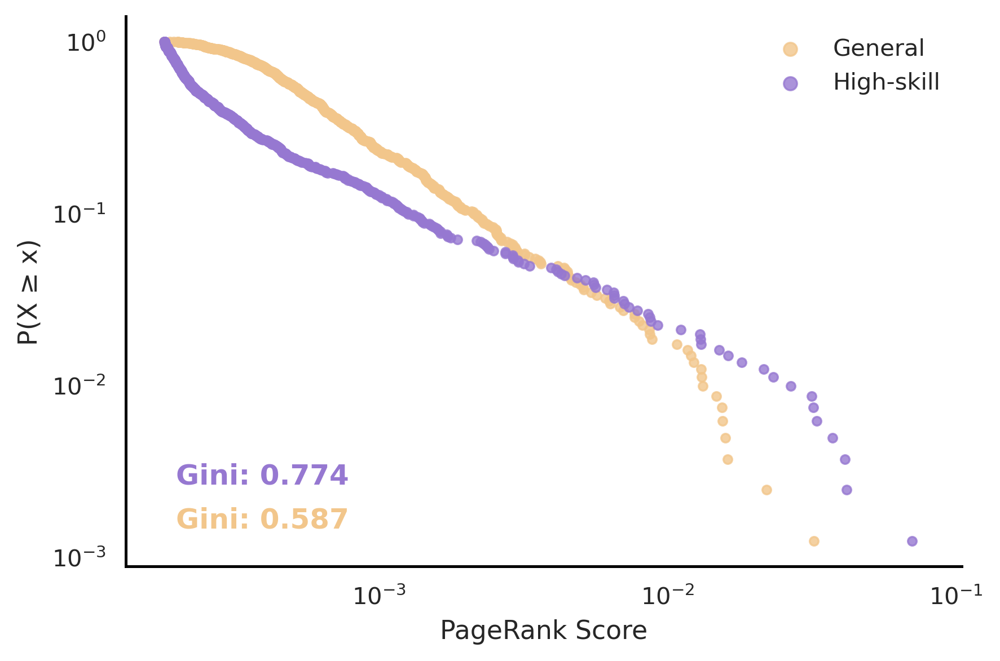

In [51]:
fig, axes = plt.subplots(1, 1, figsize=(6,4))

# ---------------------------------
# 1. PAGERANK (ABSOLUTE VALUES)
# ---------------------------------
ax = axes

ax.scatter(
    pr_irs_sorted, pr_irs_ccdf,
    s=14, alpha=0.8, color='#f2c68b', label="General"
)

ax.scatter(
    pr_exp_sorted, pr_exp_ccdf,
    s=14, alpha=0.8, color='#9678d1', label="High-skill"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("PageRank Score")
ax.set_ylabel("P(X ≥ x)")
ax.set_title("")

ax.legend(frameon=False, loc='upper right', markerscale=1.5)

# Aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis='both', which='both', length=5)

# Add Gini coefficients as text
ax.text(
    0.06, 0.15,
    f"Gini: {gini_exp:.3f}",
    weight="semibold",
    transform=ax.transAxes,
    color="#9678d1",
    fontsize=12,
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.8,
        pad=3
    )
)

ax.text(
    0.06, 0.07,
    f"Gini: {gini_irs:.3f}",
    weight="semibold",
    transform=ax.transAxes,
    color="#f2c68b",
    fontsize=12,
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.8,
        pad=3
    )
)


plt.tight_layout()
plt.show()

In [52]:
hits_merged = classify_per_window(df=hits_merged, centrality="pagerank", log_fn=np.log10)

In [53]:
# Extreme PuOr (higher contrast)
colors_strong = [
    "#7f3b08",   # very deep burnt orange
    "#f2c68b",   # soft orange
    "#fcead6",   # very light near-white
    "#9678d1",   # strong lavender/purple
    "#3f007d"    # very deep purple
]

strong_puor = mcolors.LinearSegmentedColormap.from_list(
    "StrongPuOr", colors_strong, N=256
)

# Example normalization (center = 0)
norm = mcolors.TwoSlopeNorm(vmin=hits_merged["d"].min(),
                            vcenter=0,
                            vmax=1)

In [54]:
cbsa_gdf=cbsa_gdf.merge(hits_merged[['CBSA', 'd']], on='CBSA', how='left')

cbsa_gdf["color"] = [
    tuple(strong_puor(norm(v))) if pd.notnull(v) else np.nan
    for v in cbsa_gdf["d"]
]

In [55]:
# Top 5 brain hubs (highest d)
brain_hubs = cbsa_gdf.sort_values("d", ascending=False).head(7)

# Top 5 mass hubs (lowest d)
mass_hubs = cbsa_gdf.sort_values("d", ascending=True).head(7)

print("Brain hubs:\n", brain_hubs[["CBSA","name","d"]])
print("\nMass hubs:\n", mass_hubs[["CBSA","name","d"]])

Brain hubs:
       CBSA                                          name         d
748  41860             San Francisco-Oakland-Fremont, CA  0.697794
749  41940            San Jose-Sunnyvale-Santa Clara, CA  0.668361
58   12420              Austin-Round Rock-San Marcos, TX  0.419416
764  42660                   Seattle-Tacoma-Bellevue, WA  0.417845
104  14460                Boston-Cambridge-Newton, MA-NH  0.415795
886  47900  Washington-Arlington-Alexandria, DC-VA-MD-WV  0.362149
224  19740                  Denver-Aurora-Centennial, CO  0.356032

Mass hubs:
       CBSA                          name         d
262  21340                   El Paso, TX -0.894616
436  28660            Killeen-Temple, TX -0.887386
857  46520            Urban Honolulu, HI -0.885282
167  17300            Clarksville, TN-KY -0.879783
282  22180              Fayetteville, NC -0.868501
351  25060           Gulfport-Biloxi, MS -0.750625
388  26580  Huntington-Ashland, WV-KY-OH -0.728919


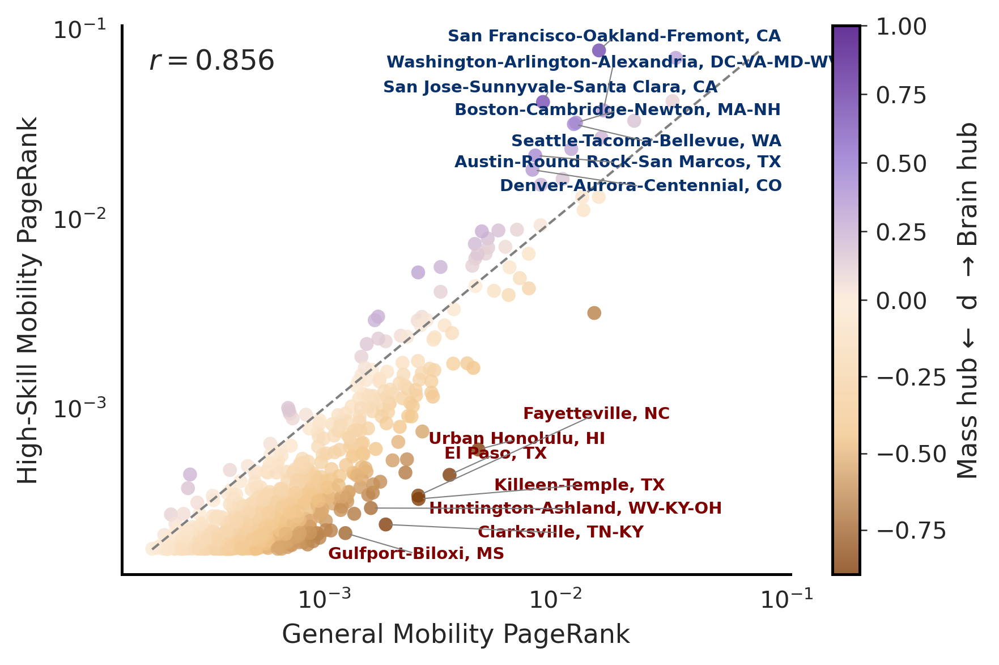

In [56]:
exp = hits_merged["pagerank_exp"]
irs = hits_merged["pagerank_irs"]

r, pval = pearsonr(irs, exp)
label = fr"$r = {r:.3f}$"

fig, ax = plt.subplots(figsize=(6,4))

sc = ax.scatter(
    irs, exp,
    c=hits_merged["d"], cmap=strong_puor,
    norm=norm,
    s=35, edgecolor="none", alpha=0.8
)

# Diagonal reference
lims = [min(exp.min(), irs.min()), max(exp.max(), irs.max())]
ax.plot(lims, lims, "--", color="gray", linewidth=1)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("General Mobility PageRank")
ax.set_ylabel("High-Skill Mobility PageRank")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis='both')

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Mass hub ←  d  → Brain hub")

texts = []

# BRAIN hubs
for _, row in brain_hubs.iterrows():
    x = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "pagerank_irs"].values[0]
    y = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "pagerank_exp"].values[0]

    t = ax.text(
        x, y, row["name"],
        fontsize=7, weight="bold", color="#08306B"
    )
    texts.append(t)

# MASS hubs
for _, row in mass_hubs.iterrows():
    x = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "pagerank_irs"].values[0]
    y = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "pagerank_exp"].values[0]

    t = ax.text(
        x, y, row["name"],
        fontsize=7, weight="bold", color="#7F0000"
    )
    texts.append(t)

adjust_text(
    texts, 
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5),
    expand_text=(1.6, 1.8),
    expand_points=(1.4, 1.6),
    force_text=(0.8, 1.0),
    force_points=(0.6, 0.8),
    lim=200,
)

# Pearson corr text
ax.text(
    0.04, 0.96,
    label,
    transform=ax.transAxes,
    fontsize=12,
    weight="bold",
    va="top",
    ha="left",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.8,
        pad=3
    )
)


plt.tight_layout()
plt.show()

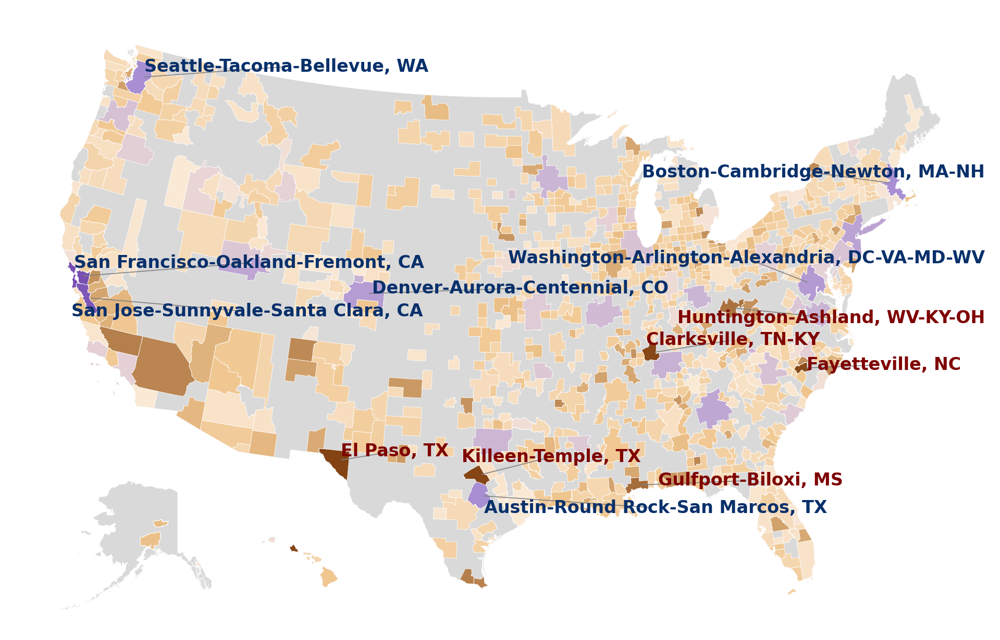

In [57]:
# -------------------------------------------------------
# Split counties into regions
# -------------------------------------------------------

not_conus=['02',  # Alaska
             '15',  # Hawaii
             '72',  # Puerto Rico
             '78',  # U.S. Virgin Islands
             '60',  # American Samoa
             '66',  # Guam
             '69']  # Northern Mariana Islands

usa = cbsa_gdf.to_crs("EPSG:5070") 
cbsa_gdf = cbsa_gdf.to_crs("EPSG:4269")

conus = usa[~usa["STATEFP"].isin(not_conus)]
alaska = cbsa_gdf[cbsa_gdf["STATEFP"] == "02"].copy()
hawaii = cbsa_gdf[cbsa_gdf["STATEFP"] == "15"].copy()

# Background polygons
counties = counties.to_crs("EPSG:5070")
conus_outline = counties[~counties["STATEFP"].isin(not_conus)][["geometry"]].dissolve()
counties = counties.to_crs("EPSG:4269")
alaska_outline = counties[counties["STATEFP"] == "02"][["geometry"]].dissolve()
hawaii_outline = counties[counties["STATEFP"] == "15"][["geometry"]].dissolve()

conus=conus.dropna(subset='color')
alaska=alaska.dropna(subset='color')
hawaii=hawaii.dropna(subset='color')


# -------------------------------------------------------
# 1. Main CONUS map
# -------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))

# Background for CONUS as a single gray polygon
conus_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax,
    zorder=1
)

# Foreground county map
conus.plot(
    color=conus["color"],
    linewidth=0.2,
    edgecolor='white',
    ax=ax,
    legend=False,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"}
)

ax.axis("off")

# Identify the geodataframe rows for the hubs
brain_geo = conus[conus["STCOFIPS"].isin(brain_hubs["STCOFIPS"])]
mass_geo  = conus[conus["STCOFIPS"].isin(mass_hubs["STCOFIPS"])]

texts = []

# ----- Brain hubs: dark blue labels -----
for _, row in brain_geo.iterrows():
    x = row.geometry.centroid.x
    y = row.geometry.centroid.y
    t = ax.text(
        x, y, row["name"],
        fontsize=8, weight="bold",
        color="#08306B",      # dark blue
        zorder=10
    )
    texts.append(t)

# ----- Mass hubs: dark red labels -----
for _, row in mass_geo.iterrows():
    x = row.geometry.centroid.x
    y = row.geometry.centroid.y
    t = ax.text(
        x, y, row["name"],
        fontsize=8, weight="bold",
        color="#7F0000",      # dark red
        zorder=10
    )
    texts.append(t)

# Now adjust so labels don't overlap
adjust_text(
    texts, ax=ax,
    expand_points=(1.2, 1.2),
    expand_text=(1.2, 1.2),
    arrowprops=dict(arrowstyle="-", lw=0.4, color="gray"),
    force_points=0.5,
    force_text=0.7
)


# -------------------------------------------------------
# 2. ALASKA INSET
# -------------------------------------------------------
ax_ak = inset_axes(
    ax,
    width="75%", height="75%",   # size relative to main axes
    loc="lower left",
    bbox_to_anchor=(0.00, 0.00, 0.3, 0.3),  # fine-tune position
    bbox_transform=ax.transAxes
)

ax_ak.axis("off")

# Background for Alaska
alaska_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax_ak,
    zorder=1
)

# Alaska counties with pagerank
alaska.plot(
    color=alaska["color"],
    linewidth=0.3,
    edgecolor="white",
    ax=ax_ak,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"}
)

# Set xlim/ylim in EPSG:4269 coordinates (degrees)
ax_ak.set_xlim(-180, -129)
ax_ak.set_ylim(51, 72)


# -------------------------------------------------------
# 3. HAWAII INSET
# -------------------------------------------------------
ax_hi = inset_axes(
    ax, width="50%", height="50%", loc="lower left",
    bbox_to_anchor=(0.22, 0.02, 0.25, 0.25),  # position
    bbox_transform=ax.transAxes
)

ax_hi.set_axis_off()

hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi)
hawaii.plot(
    color=hawaii["color"],
    linewidth=0,
    ax=ax_hi,
    alpha=0.95,
    missing_kwds={"color": "none"}
)

ax_hi.set_xlim(-161, -154)
ax_hi.set_ylim(18, 23)

plt.show()

### For SI-7: CBSA without probabilistic assignment

In [58]:
counties = load_counties()


In [59]:
hits_exp_all = pd.read_parquet("../data_generated/network_metrics/cbsa_hits_exp_1122.parquet")
hits_irs_all = pd.read_parquet("../data_generated/network_metrics/cbsa_hits_irs_1122.parquet")
cbsa = load_cbsa()


In [60]:
counties=counties.merge(cbsa[['CBSA Code', 'CBSA Title', 'STCOFIPS']], on='STCOFIPS', how='left')

cbsa_gdf = counties.dissolve(
    by='CBSA Code',
    as_index=False
)

cbsa_gdf=cbsa_gdf.drop(columns=['name'])
cbsa_gdf=cbsa_gdf.rename(columns={'CBSA Title':'name', 'CBSA Code':'CBSA'})

In [61]:
hits_merged=hits_exp_all.merge(hits_irs_all, on='CBSA', how='inner', suffixes=('_exp', '_irs'))

In [62]:
hits_merged['pagerank_exp'].sum()

0.9870286623140527

In [63]:
# Extract both pagerank series
df = hits_merged[['pagerank_exp', 'pagerank_irs']].copy()

df = df.dropna(subset=['pagerank_exp', 'pagerank_irs'])

exp_sorted = np.sort(df['pagerank_exp'])[::-1]
irs_sorted = np.sort(df['pagerank_irs'])[::-1]

ranks_exp = np.arange(1, len(exp_sorted) + 1)
ranks_irs = np.arange(1, len(irs_sorted) + 1)

gini_exp = gini(hits_merged["pagerank_exp"])
gini_irs = gini(hits_merged["pagerank_irs"])

print(gini_exp)
print(gini_irs)

0.7735357377939582
0.5885494993354898


In [64]:
pr_exp_sorted, pr_exp_ccdf = compute_ccdf(df['pagerank_exp'].values)
pr_irs_sorted, pr_irs_ccdf = compute_ccdf(df['pagerank_irs'].values)

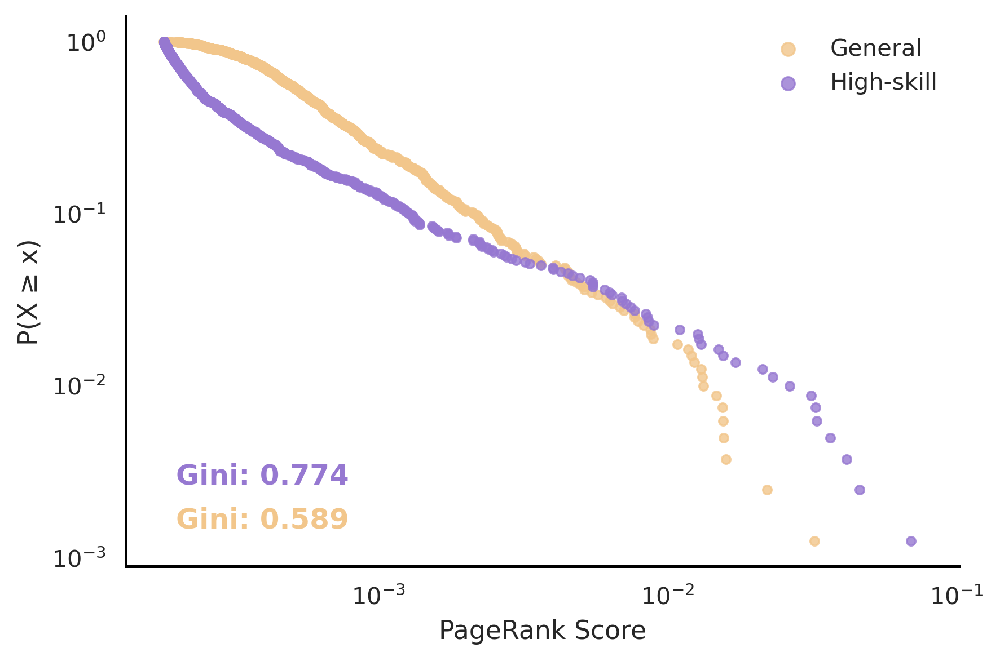

In [65]:
fig, axes = plt.subplots(1, 1, figsize=(6,4))

# ---------------------------------
# 1. PAGERANK (ABSOLUTE VALUES)
# ---------------------------------
ax = axes

ax.scatter(
    pr_irs_sorted, pr_irs_ccdf,
    s=14, alpha=0.8, color='#f2c68b', label="General"
)

ax.scatter(
    pr_exp_sorted, pr_exp_ccdf,
    s=14, alpha=0.8, color='#9678d1', label="High-skill"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("PageRank Score")
ax.set_ylabel("P(X ≥ x)")
ax.set_title("")

ax.legend(frameon=False, loc='upper right', markerscale=1.5)

# Aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis='both', which='both', length=5)

# Add Gini coefficients as text
ax.text(
    0.06, 0.15,
    f"Gini: {gini_exp:.3f}",
    weight="semibold",
    transform=ax.transAxes,
    color="#9678d1",
    fontsize=12,
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.8,
        pad=3
    )
)

ax.text(
    0.06, 0.07,
    f"Gini: {gini_irs:.3f}",
    weight="semibold",
    transform=ax.transAxes,
    color="#f2c68b",
    fontsize=12,
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.8,
        pad=3
    )
)


plt.tight_layout()
plt.show()

In [66]:
hits_merged = classify_per_window(df=hits_merged, centrality="pagerank", log_fn=np.log10)

In [67]:
# Extreme PuOr (higher contrast)
colors_strong = [
    "#7f3b08",   # very deep burnt orange
    "#f2c68b",   # soft orange
    "#fcead6",   # very light near-white
    "#9678d1",   # strong lavender/purple
    "#3f007d"    # very deep purple
]

strong_puor = mcolors.LinearSegmentedColormap.from_list(
    "StrongPuOr", colors_strong, N=256
)

# Example normalization (center = 0)
norm = mcolors.TwoSlopeNorm(vmin=hits_merged["d"].min(),
                            vcenter=0,
                            vmax=1)

In [68]:
cbsa_gdf=cbsa_gdf.merge(hits_merged[['CBSA', 'd']], on='CBSA', how='left')

cbsa_gdf["color"] = [
    tuple(strong_puor(norm(v))) if pd.notnull(v) else np.nan
    for v in cbsa_gdf["d"]
]

In [69]:
# Top 5 brain hubs (highest d)
brain_hubs = cbsa_gdf.sort_values("d", ascending=False).head(7)

# Top 5 mass hubs (lowest d)
mass_hubs = cbsa_gdf.sort_values("d", ascending=True).head(7)

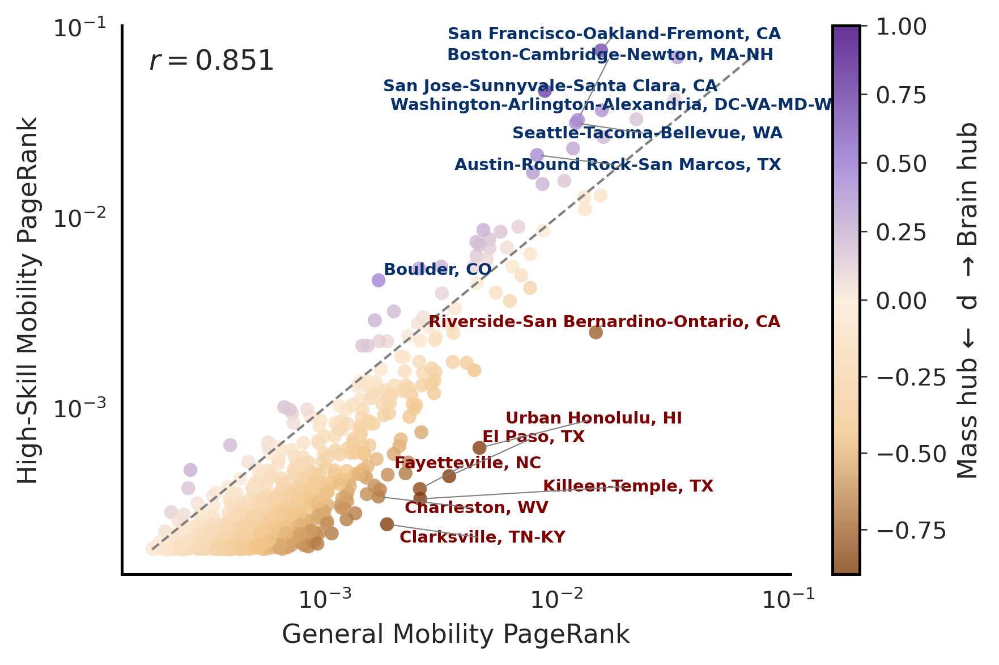

In [70]:
exp = hits_merged["pagerank_exp"]
irs = hits_merged["pagerank_irs"]

r, pval = pearsonr(irs, exp)
label = fr"$r = {r:.3f}$"

fig, ax = plt.subplots(figsize=(6,4))

sc = ax.scatter(
    irs, exp,
    c=hits_merged["d"], cmap=strong_puor,
    norm=norm,
    s=35, edgecolor="none", alpha=0.8
)

# Diagonal reference
lims = [min(exp.min(), irs.min()), max(exp.max(), irs.max())]
ax.plot(lims, lims, "--", color="gray", linewidth=1)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("General Mobility PageRank")
ax.set_ylabel("High-Skill Mobility PageRank")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis='both')

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Mass hub ←  d  → Brain hub")

texts = []

# BRAIN hubs
for _, row in brain_hubs.iterrows():
    x = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "pagerank_irs"].values[0]
    y = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "pagerank_exp"].values[0]

    t = ax.text(
        x, y, row["name"],
        fontsize=7, weight="bold", color="#08306B"
    )
    texts.append(t)

# MASS hubs
for _, row in mass_hubs.iterrows():
    x = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "pagerank_irs"].values[0]
    y = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "pagerank_exp"].values[0]

    t = ax.text(
        x, y, row["name"],
        fontsize=7, weight="bold", color="#7F0000"
    )
    texts.append(t)

adjust_text(
    texts, 
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5),
    expand_text=(1.6, 1.8),
    expand_points=(1.4, 1.6),
    force_text=(0.8, 1.0),
    force_points=(0.6, 0.8),
    lim=200,
)

# Pearson corr text
ax.text(
    0.04, 0.96,
    label,
    transform=ax.transAxes,
    fontsize=12,
    weight="bold",
    va="top",
    ha="left",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.8,
        pad=3
    )
)


plt.tight_layout()
plt.show()

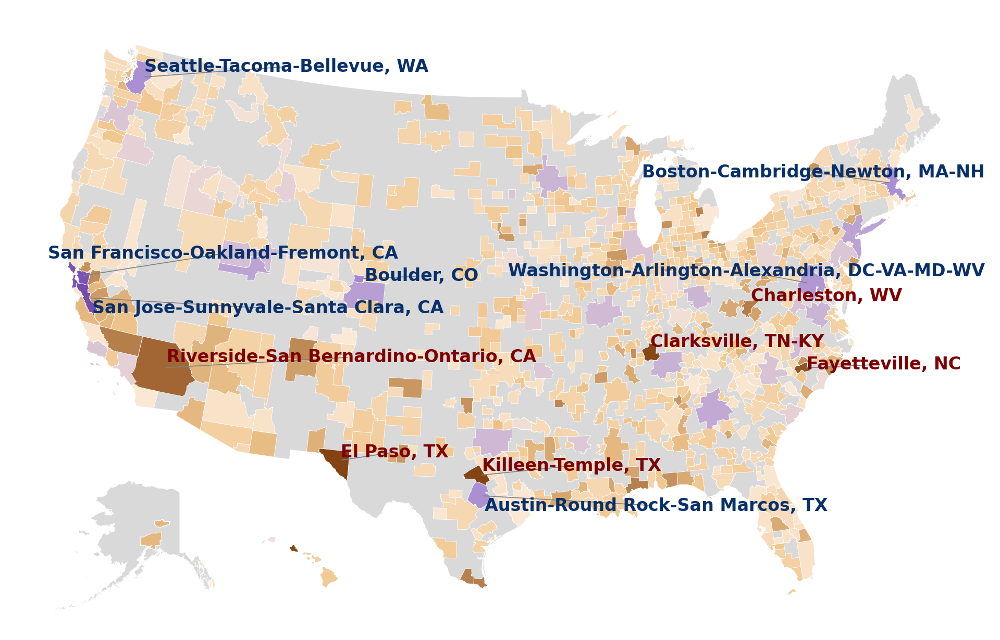

In [71]:
# -------------------------------------------------------
# Split counties into regions
# -------------------------------------------------------

not_conus=['02',  # Alaska
             '15',  # Hawaii
             '72',  # Puerto Rico
             '78',  # U.S. Virgin Islands
             '60',  # American Samoa
             '66',  # Guam
             '69']  # Northern Mariana Islands

usa = cbsa_gdf.to_crs("EPSG:5070") 
cbsa_gdf = cbsa_gdf.to_crs("EPSG:4269")

conus = usa[~usa["STATEFP"].isin(not_conus)]
alaska = cbsa_gdf[cbsa_gdf["STATEFP"] == "02"].copy()
hawaii = cbsa_gdf[cbsa_gdf["STATEFP"] == "15"].copy()

# Background polygons
counties = counties.to_crs("EPSG:5070")
conus_outline = counties[~counties["STATEFP"].isin(not_conus)][["geometry"]].dissolve()
counties = counties.to_crs("EPSG:4269")
alaska_outline = counties[counties["STATEFP"] == "02"][["geometry"]].dissolve()
hawaii_outline = counties[counties["STATEFP"] == "15"][["geometry"]].dissolve()

conus=conus.dropna(subset='color')
alaska=alaska.dropna(subset='color')
hawaii=hawaii.dropna(subset='color')


# -------------------------------------------------------
# 1. Main CONUS map
# -------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))

# Background for CONUS as a single gray polygon
conus_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax,
    zorder=1
)

# Foreground county map
conus.plot(
    color=conus["color"],
    linewidth=0.2,
    edgecolor='white',
    ax=ax,
    legend=False,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"}
)

ax.axis("off")

# Identify the geodataframe rows for the hubs
brain_geo = conus[conus["STCOFIPS"].isin(brain_hubs["STCOFIPS"])]
mass_geo  = conus[conus["STCOFIPS"].isin(mass_hubs["STCOFIPS"])]

texts = []

# ----- Brain hubs: dark blue labels -----
for _, row in brain_geo.iterrows():
    x = row.geometry.centroid.x
    y = row.geometry.centroid.y
    t = ax.text(
        x, y, row["name"],
        fontsize=8, weight="bold",
        color="#08306B",      # dark blue
        zorder=10
    )
    texts.append(t)

# ----- Mass hubs: dark red labels -----
for _, row in mass_geo.iterrows():
    x = row.geometry.centroid.x
    y = row.geometry.centroid.y
    t = ax.text(
        x, y, row["name"],
        fontsize=8, weight="bold",
        color="#7F0000",      # dark red
        zorder=10
    )
    texts.append(t)

# Now adjust so labels don't overlap
adjust_text(
    texts, ax=ax,
    expand_points=(1.2, 1.2),
    expand_text=(1.2, 1.2),
    arrowprops=dict(arrowstyle="-", lw=0.4, color="gray"),
    force_points=0.5,
    force_text=0.7
)


# -------------------------------------------------------
# 2. ALASKA INSET
# -------------------------------------------------------
ax_ak = inset_axes(
    ax,
    width="75%", height="75%",   # size relative to main axes
    loc="lower left",
    bbox_to_anchor=(0.00, 0.00, 0.3, 0.3),  # fine-tune position
    bbox_transform=ax.transAxes
)

ax_ak.axis("off")

# Background for Alaska
alaska_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax_ak,
    zorder=1
)

# Alaska counties with pagerank
alaska.plot(
    color=alaska["color"],
    linewidth=0.3,
    edgecolor="white",
    ax=ax_ak,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"}
)

# Set xlim/ylim in EPSG:4269 coordinates (degrees)
ax_ak.set_xlim(-180, -129)
ax_ak.set_ylim(51, 72)


# -------------------------------------------------------
# 3. HAWAII INSET
# -------------------------------------------------------
ax_hi = inset_axes(
    ax, width="50%", height="50%", loc="lower left",
    bbox_to_anchor=(0.22, 0.02, 0.25, 0.25),  # position
    bbox_transform=ax.transAxes
)

ax_hi.set_axis_off()

hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi)
hawaii.plot(
    color=hawaii["color"],
    linewidth=0,
    ax=ax_hi,
    alpha=0.95,
    missing_kwds={"color": "none"}
)

ax_hi.set_xlim(-161, -154)
ax_hi.set_ylim(18, 23)

plt.show()